# Prediksi Churn Industri Gas Alam
### Random Forest · XGBoost · Hybrid Soft Voting · SMOTE-Tomek · SHAP · Streamlit

- `segment` **dan `contract_status` di-One-Hot Encoding dalam pipeline training utama** untuk ketiga model (RF, XGBoost, dan Hybrid Voting).
- `bill_avg_6m` tetap melewati imputasi numerik dan `StandardScaler`.
- SMOTE-Tomek tetap berada **di dalam pipeline training**; pembagian train/validation/test dan seluruh output EDA, Confusion Matrix, ROC-AUC, SHAP, ekspor model, dan dashboard tetap dipertahankan.
- Dashboard tetap mengklasifikasikan **Churn Yes / HIGH RISK** dan **Churn No / LOW RISK** menggunakan `decision_threshold` yang dipilih pada validation set.
- One-Hot Encoding `contract_status` pada Training Utama


## 0 — Persiapan Python lokal (VS Code)

Buka **Terminal** di VS Code dan instal dependensi dengan `python -m pip install -r requirements.txt` dalam virtual environment yang sudah diaktifkan. Jalankan sel di bawah untuk memastikan notebook bekerja di folder proyek yang tepat. **Tidak ada proses upload atau download Google Colab.**


In [5]:
# Instal paket via terminal VS Code jika belum tersedia:
# python -m pip install pandas numpy openpyxl scikit-learn imbalanced-learn xgboost shap matplotlib seaborn joblib streamlit
import sys
from pathlib import Path
print('Python interpreter:', sys.executable)
print('Current working directory:', Path.cwd().resolve())


Python interpreter: c:\Users\outlo\AppData\Local\Programs\Python\Python312\python.exe
Current working directory: C:\Users\outlo\OneDrive\Desktop\c_niaa\261005


## 1 — Konfigurasi, library, dan folder proyek

Notebook menggunakan `dataset.xlsx` di folder proyek. Hasil training, gambar SHAP, dan `app.py` disimpan di folder kerja yang sama.

**Instruksi preprocessing dosen dipenuhi di model utama:** One-Hot Encoding untuk `segment` dan `contract_status`, serta scaling `bill_avg_6m` melalui `StandardScaler`.

**Perlu dicatat:** penggunaan `contract_status` sebagai prediktor memperkenalkan risiko *target leakage* jika data status `Terminated` baru diketahui setelah churn. Audit ini ditampilkan, bukan disembunyikan.

In [6]:
import json, warnings, zipfile
from collections import Counter
from pathlib import Path
from time import perf_counter

import joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, shap
from IPython.display import display
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import TomekLinks
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, classification_report,
    roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score)
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from xgboost import XGBClassifier

SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
# VS Code biasanya menjalankan kernel dengan cwd di folder notebook.
# Pencarian fallback juga mendukung membuka notebook dari folder induk proyek.
import os
HERE = Path.cwd().resolve()
PROJECT_CANDIDATES = [HERE, HERE / 'Proyek_Churn_Gas_Alam_VSCode', HERE.parent]
PROJECT_DIR = next((p for p in PROJECT_CANDIDATES if (p / 'dataset.xlsx').is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        'dataset.xlsx tidak ditemukan. Letakkan dataset.xlsx bersama notebook, '
        'lalu buka folder proyek di VS Code atau ubah working directory kernel.'
    )
PROJECT_DIR = PROJECT_DIR.resolve()
os.chdir(PROJECT_DIR)  # Seluruh output dan model ditulis di folder proyek yang sama
DATA_PATH = PROJECT_DIR / 'dataset.xlsx' 
SHEET = 'Master Customer Data'
OUT = Path('outputs_optimasi')
OUT.mkdir(exist_ok=True)
INCLUDE_LOCATION = True
CV_FOLDS = 5
TUNING_ITERATIONS = 32      # 32 kombinasi per model × 5-fold CV; set 4 untuk uji cepat
TUNING_OBJECTIVE = 'Accuracy' # Fokus pada accuracy CV; tetap pantau Recall/F1/AUC secara bersamaan
TARGET_ACCURACY = 0.85       # TARGET PENELITIAN, bukan nilai hasil yang dijamin
MIN_VALIDATION_RECALL = 0.25  # Hindari 'akurasi tinggi' karena hanya menebak kelas No
SHAP_BACKGROUND_N = 12      # background untuk SHAP; pertimbangkan dinaikkan jika komputasi tersedia
SHAP_EXPLAIN_N = 32       # lebih banyak pelanggan untuk SHAP global, tidak mewakili seluruh populasi
RUN_CONTRACT_DIAGNOSTIC = True  # ablation tambahan TANPA contract_status di validation, bukan training utama

print('Folder proyek:', PROJECT_DIR)
print('Dataset:', DATA_PATH, '| SHAP:', shap.__version__)
print('Grafik disimpan di:', OUT.resolve())
print(f'Pengaturan optimasi: {TUNING_ITERATIONS} kandidat × {CV_FOLDS} fold per model | Refitting: {TUNING_OBJECTIVE}')
print('Target accuracy penelitian:',f'{TARGET_ACCURACY:.0%}', '| minimal recall Churn validation:',f'{MIN_VALIDATION_RECALL:.0%}')


Matplotlib is building the font cache; this may take a moment.
c:\Users\outlo\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Folder proyek: C:\Users\outlo\OneDrive\Desktop\c_niaa\261005
Dataset: C:\Users\outlo\OneDrive\Desktop\c_niaa\261005\dataset.xlsx | SHAP: 0.51.0
Grafik disimpan di: C:\Users\outlo\OneDrive\Desktop\c_niaa\261005\outputs_optimasi
Pengaturan optimasi: 32 kandidat × 5 fold per model | Refitting: Accuracy
Target accuracy penelitian: 85% | minimal recall Churn validation: 25%


## 2 — Data Loading & EDA awal: 500 baris + keseluruhan data
Tidak ada *downsampling* yang dipaksakan demi mengejar angka 15,2%. Ringkasan menunjukkan komposisi aktual kedua cakupan.

In [7]:
df_500_raw = pd.read_excel(DATA_PATH, sheet_name=SHEET, nrows=500)
df_raw = pd.read_excel(DATA_PATH, sheet_name=SHEET)
print('Ukuran preview:', df_500_raw.shape, '| data lengkap:', df_raw.shape)
display(df_500_raw.head(8))
summary = pd.DataFrame([
    {'Kelompok':'500 baris pertama','Total':len(df_500_raw),'Churn':int(df_500_raw['Churn'].eq('Yes').sum()),'Tidak Churn':int(df_500_raw['Churn'].eq('No').sum())},
    {'Kelompok':'Data lengkap','Total':len(df_raw),'Churn':int(df_raw['Churn'].eq('Yes').sum()),'Tidak Churn':int(df_raw['Churn'].eq('No').sum())},
])
summary['Churn Rate (%)'] = (100*summary['Churn']/summary['Total']).round(2)
display(summary)
print('Benchmark yang diminta klien: 424 tidak churn dan 76 churn = 15,2% (TIDAK ditemukan pada 500 baris ini).')

Ukuran preview: (500, 16) | data lengkap: (1806, 16)


,Cust. ID,Churn,City,State/Prov,Country,Industry Class Type,tenure_month,avg_usage_m3_6m,usage_trend,bill_avg_6m,bill_shock_pct,late_payment_6m,complaint_3m,resolution_days_avg,has_competitor,contract_status
0,168807,No,GRESIK,JAWA TIMUR,Indonesia,DIST EXTERNAL,115,249.64,Decreasing,4933406,-5.58,0,0,0.0,No,Active
1,146639,No,GRESIK,JAWA TIMUR,Indonesia,OTHERS (ONE TIME),72,391.93,Stable,6652529,-3.12,0,1,10.0,No,Active
2,172431,Yes,GRESIK,JAWA TIMUR,Indonesia,OTHERS (ONE TIME),98,444.84,Increasing,5502939,22.35,0,0,0.0,No,Terminated
3,157561,Yes,GRESIK,JAWA TIMUR,Indonesia,OTHERS (ONE TIME),104,478.48,Stable,10708751,28.85,2,2,2.2,No,Terminated
4,165129,Yes,GRESIK,JAWA TIMUR,Indonesia,OTHERS (ONE TIME),108,241.25,Increasing,4590334,9.13,3,0,0.0,No,Terminated
5,141475,No,GRESIK,JAWA TIMUR,Indonesia,CONSTRUCTION & ENGINEERING,23,270.35,Decreasing,3433971,14.20,0,3,1.0,Yes,Active
6,109916,Yes,GRESIK,JAWA TIMUR,Indonesia,OTHERS (ONE TIME),89,228.24,Increasing,3914516,28.63,1,0,0.0,No,Terminated
7,190579,No,GRESIK,JAWA TIMUR,Indonesia,CONSTRUCTION & ENGINEERING,112,54.47,Increasing,1264544,12.53,0,0,0.0,No,Active


,Kelompok,Total,Churn,Tidak Churn,Churn Rate (%)
0,500 baris pertama,500,156,344,31.2
1,Data lengkap,1806,531,1275,29.4


Benchmark yang diminta klien: 424 tidak churn dan 76 churn = 15,2% (TIDAK ditemukan pada 500 baris ini).


## 3 — Missing value, label, dan fitur tambahan yang tersedia saat prediksi
Feature engineering hanya dari kolom pelanggan yang dapat diketahui sebelum keputusan churn (bukan dari target). `Cust. ID` disimpan untuk dashboard, tetapi tidak dipakai sebagai fitur.

In [8]:
def prepare_data(raw):
    d = raw.copy()
    d.columns = d.columns.astype(str).str.strip()
    d['Cust. ID'] = d['Cust. ID'].astype(str).str.strip()
    d['Churn'] = d['Churn'].astype(str).str.strip().str.title()
    d['segment'] = d['Industry Class Type']
    for c in ['tenure_month','avg_usage_m3_6m','bill_avg_6m','bill_shock_pct',
              'late_payment_6m','complaint_3m','resolution_days_avg']:
        d[c] = pd.to_numeric(d[c], errors='coerce')
    for c in ['segment','usage_trend','has_competitor','contract_status','City','State/Prov']:
        d[c] = d[c].map(lambda v: v.strip() if isinstance(v,str) else np.nan).replace('',np.nan)
    # Interaksi deterministik, dihitung juga di app.py untuk inference
    tenure_safe = d['tenure_month'].clip(lower=1)
    d['complaint_per_year'] = d['complaint_3m'] * 12 / tenure_safe
    d['late_payment_per_year'] = d['late_payment_6m'] * 12 / tenure_safe
    d['bill_shock_x_declining'] = d['bill_shock_pct'] * d['usage_trend'].eq('Decreasing').astype(float)
    d = d.loc[d['Churn'].isin(['Yes','No'])].copy()
    d['churn_flag'] = d['Churn'].map({'No':0,'Yes':1}).astype(int)
    return d

df = prepare_data(df_raw)
df_500 = prepare_data(df_500_raw)
quality = pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'unique':df.nunique(dropna=True)})
display(quality)
print('Duplicate Cust. ID:', df['Cust. ID'].duplicated().sum())
assert not df['Cust. ID'].duplicated().any(), 'Periksa ID pelanggan duplikat sebelum split.'
assert set(df['churn_flag'].unique()) == {0,1}

,dtype,missing,unique
Cust. ID,object,0,1806
Churn,object,0,2
City,object,0,346
State/Prov,object,0,60
Country,object,0,1
Industry Class Type,object,8,14
tenure_month,int64,0,115
avg_usage_m3_6m,float64,0,1772
usage_trend,object,0,3
bill_avg_6m,int64,0,1806


Duplicate Cust. ID: 0


## 4 — Grafik EDA A: distribusi churn
Plot menggunakan data lengkap. Bandingkan juga hasil 500 baris pada tabel sebelumnya.

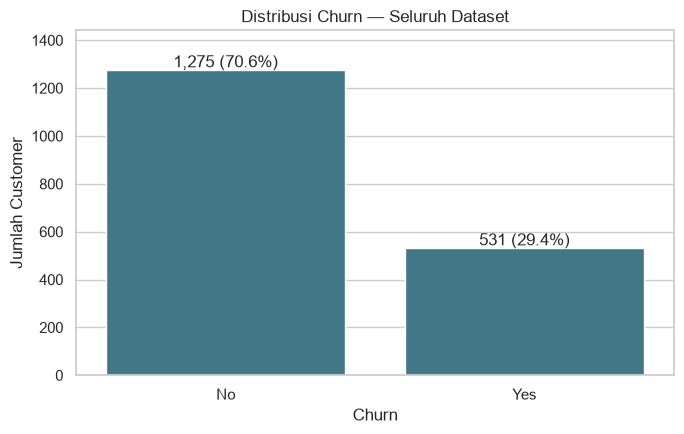

In [9]:
counts = df['Churn'].value_counts().reindex(['No','Yes'],fill_value=0)
fig,ax=plt.subplots(figsize=(7,4.5))
sns.barplot(x=counts.index,y=counts.values,ax=ax,color='#357F94')
for j,v in enumerate(counts.values):ax.text(j,v+12,f'{v:,} ({100*v/len(df):.1f}%)',ha='center')
ax.set(title='Distribusi Churn — Seluruh Dataset',xlabel='Churn',ylabel='Jumlah Customer',ylim=(0,max(counts)*1.13))
plt.tight_layout();plt.savefig(OUT/'eda_distribusi_churn.png',bbox_inches='tight');plt.show()

## 5 — Grafik EDA B: Tenure vs Churn
Boxplot memperlihatkan distribusi, **bukan bukti otomatis** bahwa pelanggan baru pasti lebih mudah churn. Cetak median & nilai aktual untuk interpretasi.

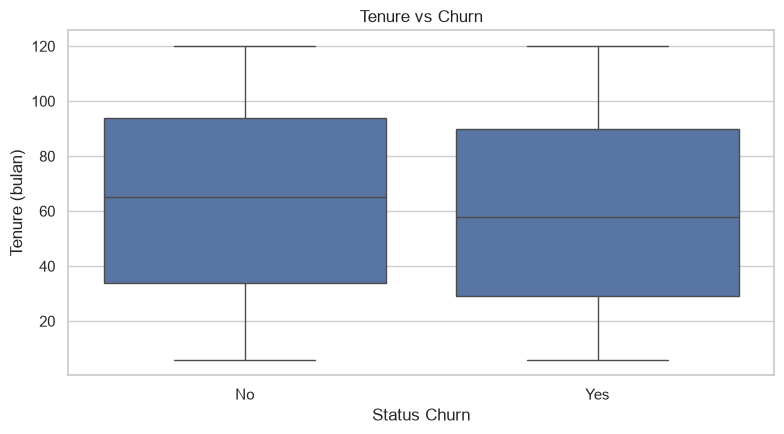

,count,mean,median,std
Churn,,,,
No,1275,64.46,65.0,33.68
Yes,531,60.51,58.0,33.97


In [10]:
fig,ax=plt.subplots(figsize=(8,4.5));sns.boxplot(data=df,x='Churn',y='tenure_month',order=['No','Yes'],ax=ax)
ax.set(title='Tenure vs Churn',xlabel='Status Churn',ylabel='Tenure (bulan)')
plt.tight_layout();plt.savefig(OUT/'eda_boxplot_tenure.png',bbox_inches='tight');plt.show()
display(df.groupby('Churn')['tenure_month'].agg(['count','mean','median','std']).round(2))

## 6 — Grafik EDA C: Korelasi fitur numerik
Nilai korelasi **tidak boleh direkayasa** agar `complaint_3m` dan `bill_shock_pct` tampak kuat. Korelasi Pearson yang rendah tidak menutup kemungkinan pola non-linear; nanti SHAP membantu penjelasan model.

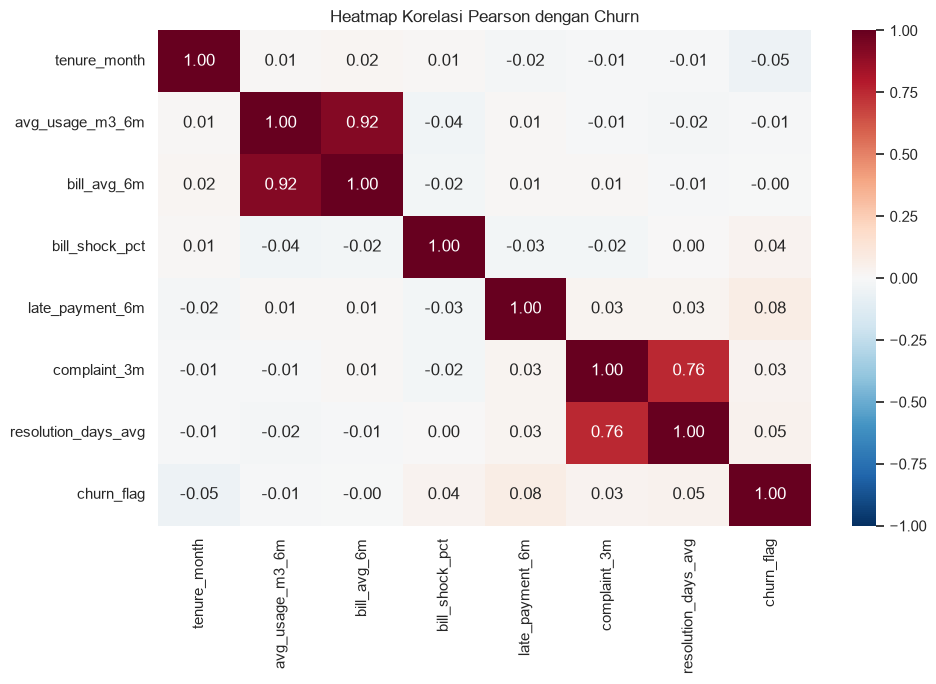

,Pearson r
late_payment_6m,0.075487
tenure_month,-0.053291
resolution_days_avg,0.046604
bill_shock_pct,0.035087
complaint_3m,0.034177
avg_usage_m3_6m,-0.013200
bill_avg_6m,-0.003765


In [11]:
corr_features = ['tenure_month','avg_usage_m3_6m','bill_avg_6m','bill_shock_pct',
                 'late_payment_6m','complaint_3m','resolution_days_avg','churn_flag']
corr=df[corr_features].corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(10,7));sns.heatmap(corr,annot=True,fmt='.2f',cmap='RdBu_r',vmin=-1,vmax=1,center=0,ax=ax)
ax.set_title('Heatmap Korelasi Pearson dengan Churn');plt.tight_layout()
plt.savefig(OUT/'eda_heatmap_korelasi.png',bbox_inches='tight');plt.show()
display(corr['churn_flag'].drop('churn_flag').sort_values(key=abs,ascending=False).to_frame('Pearson r'))

## 7 — Audit ketergantungan label pada `contract_status`

`contract_status` **akan dimasukkan ke seluruh model utama** sesuai instruksi dosen. Tabel silang berikut digunakan untuk memperlihatkan risiko informasi pascakejadian (contoh status `Terminated`).

**Jangan menganggap tingginya metrik model dengan `Terminated` sebagai bukti prediksi churn sebelum terjadi** tanpa memverifikasi bahwa status kontrak tersedia pada saat keputusan prediksi.

In [12]:
display(pd.crosstab(df['contract_status'], df['Churn'], margins=True))
terminated = df['contract_status'].eq('Terminated')
if terminated.any():
    print('Jumlah Terminated:', int(terminated.sum()))
    print('Persentase churn pada Terminated:', f"{df.loc[terminated, 'churn_flag'].mean():.1%}")
print('CATATAN: contract_status akan digunakan sebagai fitur TRAINING UTAMA sesuai instruksi dosen.')
print('RISIKO: Jika Terminated tercatat setelah kejadian churn, skor model tidak mewakili prediksi sebelum churn.')

Churn,No,Yes,All
contract_status,,,
Active,979,28,1007
Expiring Soon,164,34,198
Terminated,0,461,461
Under Renewal,132,8,140
All,1275,531,1806


Jumlah Terminated: 461
Persentase churn pada Terminated: 100.0%
CATATAN: contract_status akan digunakan sebagai fitur TRAINING UTAMA sesuai instruksi dosen.
RISIKO: Jika Terminated tercatat setelah kejadian churn, skor model tidak mewakili prediksi sebelum churn.


## 8 — Fitur dan split: Train / Validation / Test
Test 20% ditahan sampai pemilihan model dan threshold selesai. Semua preprocessing, SMOTE, serta tuning dilakukan **hanya pada training atau CV-fold training**; validation digunakan hanya untuk bobot Hybrid & threshold.

In [13]:
BASE_NUM = ['tenure_month','avg_usage_m3_6m','bill_avg_6m','bill_shock_pct','late_payment_6m',
            'complaint_3m','resolution_days_avg','complaint_per_year','late_payment_per_year','bill_shock_x_declining']
BASE_CAT = ['segment','contract_status','usage_trend','has_competitor'] + (['City','State/Prov'] if INCLUDE_LOCATION else [])
FEATURES = BASE_NUM + BASE_CAT
X=df[FEATURES].copy();y=df['churn_flag'].copy()
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=0.20,stratify=y,random_state=SEED)
X_train,X_val,y_train,y_val=train_test_split(X_dev,y_dev,test_size=0.20,stratify=y_dev,random_state=SEED)
splits=pd.DataFrame([{'Split':nm,'Jumlah':len(yi),'Churn':int(yi.sum()),'Tidak churn':int((yi==0).sum()),'Churn Rate':yi.mean()} for nm,yi in [('Train',y_train),('Validation',y_val),('Test',y_test)]])
display(splits)
print('Fitur numerik (StandardScaler termasuk bill_avg_6m):', BASE_NUM)
print('Fitur kategorikal (One-Hot wajib: segment dan contract_status):', BASE_CAT)
assert {'segment', 'contract_status'}.issubset(set(BASE_CAT))
assert {'segment', 'contract_status'}.issubset(set(FEATURES))
print('Accuracy baseline selalu prediksi Tidak Churn (test):',f'{(y_test==0).mean():.2%}')

,Split,Jumlah,Churn,Tidak churn,Churn Rate
0,Train,1155,340,815,0.294372
1,Validation,289,85,204,0.294118
2,Test,362,106,256,0.292818


Fitur numerik (StandardScaler termasuk bill_avg_6m): ['tenure_month', 'avg_usage_m3_6m', 'bill_avg_6m', 'bill_shock_pct', 'late_payment_6m', 'complaint_3m', 'resolution_days_avg', 'complaint_per_year', 'late_payment_per_year', 'bill_shock_x_declining']
Fitur kategorikal (One-Hot wajib: segment dan contract_status): ['segment', 'contract_status', 'usage_trend', 'has_competitor', 'City', 'State/Prov']
Accuracy baseline selalu prediksi Tidak Churn (test): 70.72%


## 9 — Preprocessing dan SMOTE-Tomek **pada ketiga model utama**

- **Numerik:** imputasi median dan `StandardScaler`, termasuk `bill_avg_6m` (nama kolom tagihan rata-rata pada dataset).
- **Kategorikal utama:** `segment`, `contract_status`, `usage_trend`, dan `has_competitor` menggunakan **One-Hot Encoding**. `contract_status` **tidak lagi dibatasi pada eksperimen diagnostik**.
- **Lokasi:** `City` dan `State/Prov` diuji menggunakan One-Hot atau *cross-fitted Target Encoding* pada CV training.
- **SMOTE-Tomek:** dilakukan pada training/CV training saja. Validation dan test tidak diresample.

**Peringatan interpretasi:** `contract_status = Terminated` berpotensi diketahui setelah churn. Karena itu, evaluasi utama di notebook ini adalah evaluasi klasifikasi dengan status yang tercatat, **bukan bukti valid prediksi churn prospektif**. Selain itu, SMOTE yang dilakukan setelah One-Hot Encoding dapat menginterpolasi variabel dummy.

In [14]:
GEO_COLS = ['City','State/Prov']

def make_preprocessor(numeric, categorical, geo_encoding='onehot'):
    """TargetEncoder melakukan cross-fitting pada FIT training, bukan validation/test.

    Semua fitur categorical non-lokasi (khususnya segment dan contract_status
    pada ketiga model utama) menggunakan OneHotEncoder sesuai kebutuhan dosen.
    """
    basic_cat = [c for c in categorical if c not in GEO_COLS]
    geo_cat = [c for c in GEO_COLS if c in categorical]
    transformers = [
        ('numeric',Pipeline([('imputer',SimpleImputer(strategy='median')),
                             ('scaler',StandardScaler())]),numeric),
    ]
    if basic_cat:
        transformers.append(('categorical',Pipeline([
            ('imputer',SimpleImputer(strategy='most_frequent')),
            ('onehot',OneHotEncoder(handle_unknown='infrequent_if_exist',
                                    min_frequency=3,max_categories=20,sparse_output=False))
        ]),basic_cat))
    if geo_cat:
        if geo_encoding == 'target':
            transformers.append(('geo',Pipeline([
                ('imputer',SimpleImputer(strategy='most_frequent')),
                ('target',TargetEncoder(target_type='binary',cv=5,smooth=15,random_state=SEED))
            ]),geo_cat))
        elif geo_encoding == 'onehot':
            transformers.append(('geo',Pipeline([
                ('imputer',SimpleImputer(strategy='most_frequent')),
                ('onehot',OneHotEncoder(handle_unknown='infrequent_if_exist',
                                        min_frequency=3,max_categories=20,sparse_output=False))
            ]),geo_cat))
        else:
            raise ValueError('geo_encoding harus onehot atau target')
    return ColumnTransformer(transformers,remainder='drop',sparse_threshold=0)

def make_sampler():
    return SMOTETomek(smote=SMOTE(random_state=SEED,k_neighbors=3),
                      tomek=TomekLinks(sampling_strategy='all'),random_state=SEED)

def pipeline(estimator,numeric=BASE_NUM,categorical=BASE_CAT,geo_encoding='onehot'):
    return ImbPipeline([('preprocess',make_preprocessor(numeric,categorical,geo_encoding)),
                        ('smote_tomek',make_sampler()),('classifier',estimator)])

# Pemeriksaan SMOTE-Tomek tetap menggunakan representasi One-Hot baseline.
p_demo=make_preprocessor(BASE_NUM,BASE_CAT,geo_encoding='onehot')
mat=p_demo.fit_transform(X_train,y_train)
xs,ys=SMOTE(random_state=SEED,k_neighbors=3).fit_resample(mat,y_train)
xt,yt=TomekLinks(sampling_strategy='all').fit_resample(xs,ys)
print('TRAIN asli:',dict(Counter(y_train)))
print('Setelah SMOTE:',dict(Counter(ys)))
print('Setelah Tomek Links:',dict(Counter(yt)))
print('Validasi dan test TIDAK di-resample. Jumlah fitur One-Hot baseline:',mat.shape[1])

TRAIN asli: {0: 815, 1: 340}
Setelah SMOTE: {0: 815, 1: 815}
Setelah Tomek Links: {0: 814, 1: 814}
Validasi dan test TIDAK di-resample. Jumlah fitur One-Hot baseline: 72


### 9A — Demonstrasi angka SMOTE berdasarkan brief (BUKAN hasil populasi)

Brief menyebut **500 pelanggan = 424 Tidak Churn + 76 Churn (15,2%)**. Ini **tidak** sesuai dengan 500 baris pertama dataset (344:156). Agar alur teknis *424:76 → 424:424 → pembersihan Tomek Links* dapat diperlihatkan secara jujur, contoh berikut **sengaja mengambil 424 pelanggan tidak churn dan 76 churn dari dataset lengkap** dengan *sampling berdasarkan label*. Sampel ini **hanya untuk demonstrasi**: tidak dipakai untuk fitting, tuning, atau testing model utama, dan tidak dapat dijadikan estimasi churn rate perusahaan.

Catatan: Tomek Links dapat menghapus pasangan observasi, jadi jumlah **setelah Tomek** tidak mesti tepat 424:424. Yang dijamin SMOTE adalah 424:424 *sebelum* pembersihan Tomek.


In [15]:
# Demonstrasi terpisah yang disusun dari label aktual; BUKAN 500 baris pertama dan BUKAN data training utama.
brief_500 = pd.concat([
    df.loc[df['churn_flag'].eq(0)].sample(n=424, random_state=SEED),
    df.loc[df['churn_flag'].eq(1)].sample(n=76, random_state=SEED),
], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
brief_X = brief_500[FEATURES]
brief_y = brief_500['churn_flag']
brief_preprocessor = make_preprocessor(BASE_NUM,BASE_CAT)
brief_X_encoded = brief_preprocessor.fit_transform(brief_X)
brief_X_smote,brief_y_smote = SMOTE(random_state=SEED,k_neighbors=3).fit_resample(brief_X_encoded,brief_y)
brief_X_tomek,brief_y_tomek = TomekLinks(sampling_strategy='all').fit_resample(brief_X_smote,brief_y_smote)
assert Counter(brief_y)==Counter({0:424,1:76})
assert Counter(brief_y_smote)==Counter({0:424,1:424})
brief_comparison=pd.DataFrame([
    {'Tahap':'Sampel TERPILIH (bukan 500 pertama)','Tidak Churn':int(sum(brief_y==0)),'Churn':int(sum(brief_y==1))},
    {'Tahap':'Setelah SMOTE','Tidak Churn':int(sum(brief_y_smote==0)),'Churn':int(sum(brief_y_smote==1))},
    {'Tahap':'Setelah pembersihan Tomek','Tidak Churn':int(sum(brief_y_tomek==0)),'Churn':int(sum(brief_y_tomek==1))}
])
display(brief_comparison)
print(f"DEMONSTRASI SAJA: churn rate 500 pelanggan terpilih {brief_y.mean():.1%}; churn rate populasi ASLI {df['churn_flag'].mean():.1%}.")
print('Tidak digunakan dalam fitting maupun pengujian model utama.')


,Tahap,Tidak Churn,Churn
0,Sampel TERPILIH (bukan 500 pertama),424,76
1,Setelah SMOTE,424,424
2,Setelah pembersihan Tomek,424,424


DEMONSTRASI SAJA: churn rate 500 pelanggan terpilih 15.2%; churn rate populasi ASLI 29.4%.
Tidak digunakan dalam fitting maupun pengujian model utama.


## 10 — Optimasi Hyperparameter + Alternatif Encoding Lokasi (5-fold CV)

**Perbaikan utama V2:** sebelumnya hanya satu cara representasi fitur kota/provinsi. Sekarang masing-masing model membandingkan:

1. **One-Hot Encoding lokasi** (baseline).
2. **Target Encoding lokasi yang cross-fitted** (mengurangi dimensi lokasi ber-kardinalitas tinggi dan meminimalkan kebocoran in-fold).

Semua opsi dipilih **hanya dengan stratified CV pada training set**. `validation set` tetap disimpan untuk threshold tuning dan pemilihan model; `test set` tidak digunakan untuk mengatur hyperparameter. Pengkodean `segment` dan `contract_status` **selalu One-Hot dalam kedua opsi** dan keduanya digunakan oleh ketiga model utama.

Tujuan tuning default = **Accuracy**, tetapi pencapaian accuracy tanpa recall churn tetap harus diperiksa. `85%` adalah target aspiratif, bukan angka yang dipaksakan. Untuk uji cepat, ubah `TUNING_ITERATIONS=4` dan `CV_FOLDS=3` di sel konfigurasi, kemudian kembalikan untuk hasil akhir.

In [16]:
rf_base = RandomForestClassifier(random_state=SEED, n_jobs=1)
xgb_base = XGBClassifier(
    objective='binary:logistic', eval_metric='logloss', tree_method='hist',
    random_state=SEED, n_jobs=1
)

# Pencarian preprocessor juga tercakup di dalam cross-validation.
geo_preprocessors = [
    make_preprocessor(BASE_NUM, BASE_CAT, geo_encoding='onehot'),
    make_preprocessor(BASE_NUM, BASE_CAT, geo_encoding='target'),
]
common_resampling = {
    'preprocess': geo_preprocessors,
    'smote_tomek__smote__sampling_strategy': [0.65,0.75,0.85,1.0],
    'smote_tomek__smote__k_neighbors': [3,5],
}
rf_space = {
    **common_resampling,
    'classifier__n_estimators': [150,250,400,550],
    'classifier__max_depth': [6,9,13,None],
    'classifier__min_samples_leaf': [2,4,6,9],
    'classifier__max_features': ['sqrt',0.7,0.9],
    'classifier__class_weight': [None,'balanced_subsample'],
}
xgb_space = {
    **common_resampling,
    'classifier__n_estimators': [90,150,230,350],
    'classifier__max_depth': [2,3,4],
    'classifier__learning_rate': [0.02,0.045,0.08,0.12],
    'classifier__min_child_weight': [3,7,12,18],
    'classifier__subsample': [0.75,0.9,1.0],
    'classifier__colsample_bytree': [0.75,0.9,1.0],
    'classifier__reg_lambda': [3,8,15,24],
    'classifier__reg_alpha': [0,0.1,0.3],
}

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
scoring = {
    'ROC-AUC': 'roc_auc',
    'Accuracy': 'accuracy',
    'F1 Churn': 'f1',
    'Balanced Accuracy': 'balanced_accuracy',
    'Recall Churn': 'recall',
}
assert TUNING_OBJECTIVE in scoring
searches, cv_reports, models = {}, {}, {}
for name, estimator, space in [
    ('Random Forest', rf_base, rf_space),
    ('XGBoost', xgb_base, xgb_space),
]:
    t0 = perf_counter()
    search = RandomizedSearchCV(
        pipeline(estimator), space, n_iter=TUNING_ITERATIONS, cv=cv,
        scoring=scoring, refit=TUNING_OBJECTIVE,
        random_state=SEED, n_jobs=1, error_score='raise', verbose=0,
        return_train_score=False,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    models[name] = search.best_estimator_
    report = pd.DataFrame(search.cv_results_).sort_values(f'rank_test_{TUNING_OBJECTIVE}')
    cv_reports[name] = report
    report.to_csv(OUT / f'cv_tuning_{name.lower().replace(" ", "_")}.csv',index=False)
    best_pre=models[name].named_steps['preprocess']
    geo_sub=best_pre.named_transformers_.get('geo')
    best_encoding='target' if geo_sub is not None and 'target' in geo_sub.named_steps else 'onehot'
    print(f'{name} | CV {TUNING_OBJECTIVE}={search.best_score_:.4f} | encoding={best_encoding} '
          f'| waktu={perf_counter()-t0:.1f}s')
    print('SMOTE ratio:',models[name].named_steps['smote_tomek'].smote.sampling_strategy)
    print('Parameter utama:',{k:v for k,v in search.best_params_.items() if k!='preprocess'})
    important=[f'mean_test_{k}' for k in scoring]
    display(report[important].head(5).round(4))

Random Forest | CV Accuracy=0.9723 | encoding=target | waktu=183.0s
SMOTE ratio: 0.85
Parameter utama: {'smote_tomek__smote__sampling_strategy': 0.85, 'smote_tomek__smote__k_neighbors': 3, 'classifier__n_estimators': 550, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 0.7, 'classifier__max_depth': 9, 'classifier__class_weight': None}


,mean_test_ROC-AUC,mean_test_Accuracy,mean_test_F1 Churn,mean_test_Balanced Accuracy,mean_test_Recall Churn
29,0.9929,0.9723,0.9509,0.9555,0.9147
24,0.9938,0.9714,0.9490,0.9532,0.9088
27,0.9900,0.9706,0.9477,0.9534,0.9118
25,0.9944,0.9706,0.9478,0.9534,0.9118
2,0.9919,0.9697,0.9466,0.9537,0.9147


XGBoost | CV Accuracy=0.9758 | encoding=target | waktu=33.7s
SMOTE ratio: 1.0
Parameter utama: {'smote_tomek__smote__sampling_strategy': 1.0, 'smote_tomek__smote__k_neighbors': 5, 'classifier__subsample': 0.9, 'classifier__reg_lambda': 15, 'classifier__reg_alpha': 0.1, 'classifier__n_estimators': 350, 'classifier__min_child_weight': 3, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.045, 'classifier__colsample_bytree': 0.9}


,mean_test_ROC-AUC,mean_test_Accuracy,mean_test_F1 Churn,mean_test_Balanced Accuracy,mean_test_Recall Churn
29,0.9966,0.9758,0.9568,0.9588,0.9176
20,0.9963,0.9740,0.9538,0.9567,0.9147
19,0.9958,0.9740,0.9546,0.9610,0.9294
23,0.9963,0.9740,0.9547,0.9619,0.9324
26,0.9947,0.9740,0.9538,0.9567,0.9147


## 11 — Hybrid Soft Voting (RF + XGBoost)

Model Hybrid menggunakan **preprocessor yang sama dengan XGBoost CV-terpilih** agar kedua model internal dapat berbagi ruang fitur. Keduanya tetap dilatih dengan SMOTE-Tomek pada training set. Bobot Hybrid dipilih dari probabilitas internal Hybrid yang *benar-benar fitted* pada validation set; bukan dari classifier terpisah. Tuning bobot Hybrid ini tetap tidak melihat test set.

In [17]:
rf_tuned = clone(models['Random Forest'].named_steps['classifier'])
xgb_tuned = clone(models['XGBoost'].named_steps['classifier'])

# Untuk pipeline Hybrid, gunakan rasio SMOTE milik XGBoost yang terpilih pada CV training.
hybrid_sampling_ratio = float(
    models['XGBoost'].named_steps['smote_tomek'].smote.sampling_strategy
)
hybrid_neighbors = int(models['XGBoost'].named_steps['smote_tomek'].smote.k_neighbors)
hybrid_clf = VotingClassifier(
    estimators=[('random_forest', rf_tuned), ('xgboost', xgb_tuned)],
    voting='soft', weights=[1, 1], n_jobs=1,
)
models['Hybrid Voting'] = ImbPipeline([
    ('preprocess', clone(models['XGBoost'].named_steps['preprocess'])),
    ('smote_tomek', make_sampler()),
    ('classifier', hybrid_clf),
])
models['Hybrid Voting'].set_params(
    smote_tomek__smote__sampling_strategy=hybrid_sampling_ratio,
    smote_tomek__smote__k_neighbors=hybrid_neighbors,
)
t0 = perf_counter()
models['Hybrid Voting'].fit(X_train, y_train)

# Kedua probabilitas berikut berasal dari ESTIMATOR FITTED DI DALAM HYBRID,
# bukan dari model RF dan XGBoost yang di-fit secara independen.
hybrid_pre = models['Hybrid Voting'].named_steps['preprocess']
X_val_hybrid_encoded = hybrid_pre.transform(X_val)
hybrid_fitted_clf = models['Hybrid Voting'].named_steps['classifier']
p_rf_hybrid = hybrid_fitted_clf.named_estimators_['random_forest'].predict_proba(X_val_hybrid_encoded)[:, 1]
p_xgb_hybrid = hybrid_fitted_clf.named_estimators_['xgboost'].predict_proba(X_val_hybrid_encoded)[:, 1]

weight_rows = []
for w_rf, w_xgb in [(1,1), (1,2), (2,1), (1,3), (3,1), (1,4), (4,1), (1,5), (5,1)]:
    p = (w_rf*p_rf_hybrid + w_xgb*p_xgb_hybrid) / (w_rf+w_xgb)
    weight_rows.append({
        'RF': w_rf, 'XGB': w_xgb,
        'ROC-AUC Validation': roc_auc_score(y_val, p),
        'Accuracy @0.50': accuracy_score(y_val, p >= 0.5),
        'Recall @0.50': recall_score(y_val, p >= 0.5, zero_division=0),
    })
weight_table = pd.DataFrame(weight_rows).sort_values(
    ['ROC-AUC Validation','Recall @0.50','Accuracy @0.50'], ascending=False
)
display(weight_table.round(4))
W_RF, W_XGB = weight_table.iloc[0][['RF','XGB']].astype(int)
hybrid_fitted_clf.weights = [int(W_RF), int(W_XGB)]

# Verifikasi: weighted average yang dipilih sama dengan output VotingClassifier akhir.
selected_weighted_p = (W_RF*p_rf_hybrid + W_XGB*p_xgb_hybrid) / (W_RF+W_XGB)
assert np.allclose(
    models['Hybrid Voting'].predict_proba(X_val)[:,1], selected_weighted_p,
    rtol=1e-7, atol=1e-9
), 'Probabilitas pemilihan bobot dan Hybrid akhir tidak konsisten.'
print('Hybrid Voting terlatih | Bobot:', [int(W_RF), int(W_XGB)],
      '| SMOTE ratio:', hybrid_sampling_ratio,
      '| waktu:', round(perf_counter()-t0,1), 'detik')


,RF,XGB,ROC-AUC Validation,Accuracy @0.50,Recall @0.50
7,1,5,0.9993,0.9827,0.9647
3,1,3,0.9993,0.9827,0.9647
5,1,4,0.9993,0.9827,0.9647
1,1,2,0.9992,0.9827,0.9647
0,1,1,0.9990,0.9862,0.9765
2,2,1,0.9984,0.9862,0.9765
4,3,1,0.9983,0.9862,0.9765
6,4,1,0.9983,0.9862,0.9765
8,5,1,0.9982,0.9862,0.9765


Hybrid Voting terlatih | Bobot: [1, 5] | SMOTE ratio: 1.0 | waktu: 2.7 detik


## 12 — Threshold tuning + pemilihan model (VALIDATION saja)

Threshold tidak dilatih sebagai parameter bawaan XGBoost/RF. Setelah classifier memperoleh probabilitas, threshold biner dipilih di **validation set**, dengan tujuan **Accuracy maksimum tetapi Recall Churn minimal 25%** (`MIN_VALIDATION_RECALL`). Parameter ini dapat disesuaikan sesuai kebijakan retensi dan dijelaskan pada skripsi. Kategori HIGH/LOW menggunakan threshold yang sama.

Model dashboard dipilih berdasarkan **accuracy validation yang sudah mempertimbangkan syarat recall**, bukan accuracy training. **Catatan:** seluruh model utama kini menggunakan `contract_status`, sehingga metriknya tidak dapat otomatis digeneralisasi sebagai prediksi sebelum churn. Tabel tetap melaporkan ROC-AUC, Precision, Recall, F1, Balanced Accuracy.

In [18]:
def metrics_at(y_true, proba, threshold):
    y_pred = (np.asarray(proba) >= threshold).astype(int)
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred),
        'Precision Churn': precision_score(y_true, y_pred, zero_division=0),
        'Recall Churn': recall_score(y_true, y_pred, zero_division=0),
        'F1 Churn': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, proba),
    }

THRESHOLD_GRID = np.round(np.arange(0.20, 0.801, 0.01), 3)
# Sertakan 0.525 dan 0.500 agar threshold asli tetap dapat dibandingkan.
THRESHOLD_GRID = np.sort(np.unique(np.r_[THRESHOLD_GRID, 0.50, 0.525]))
# MIN_VALIDATION_RECALL diatur pada sel konfigurasi; jangan ganti diam-diam.
assert 0.0 <= MIN_VALIDATION_RECALL <= 1.0
thresholds, val_stats, val_probas, threshold_candidates = {}, {}, {}, {}
for name, model in models.items():
    prob = model.predict_proba(X_val)[:,1]
    val_probas[name] = prob
    candidates = [
        {'threshold':float(t), **metrics_at(y_val, prob, float(t))}
        for t in THRESHOLD_GRID
    ]
    opts = pd.DataFrame(candidates)
    threshold_candidates[name] = opts
    eligible = opts.loc[opts['Recall Churn'] >= MIN_VALIDATION_RECALL]
    if eligible.empty:
        print(f'PERINGATAN: {name} tidak mencapai recall validasi {MIN_VALIDATION_RECALL:.0%} '
              'di rentang threshold, sehingga menggunakan kandidat tanpa batas recall.')
        eligible = opts
    chosen = eligible.sort_values(
        ['Accuracy','F1 Churn','Balanced Accuracy','Recall Churn'],
        ascending=False
    ).iloc[0]
    thresholds[name] = float(chosen['threshold'])
    val_stats[name] = {
        k:float(v) for k,v in metrics_at(y_val, prob, thresholds[name]).items()
    }
    val_stats[name]['Threshold'] = thresholds[name]
    opts.to_csv(OUT / f'threshold_validation_{name.lower().replace(" ", "_")}.csv', index=False)

val_table = pd.DataFrame(val_stats).T.sort_values(['Accuracy','Recall Churn','ROC-AUC'], ascending=False)
display(val_table.round(4))
selected_model_name = val_table.index[0]
selected_model = models[selected_model_name]
print('Model terpilih berdasarkan ACCURACY VALIDATION dengan batas recall:', selected_model_name,
      '| threshold dari validation:', f'{thresholds[selected_model_name]:.1%}')
print('Baseline mayoritas pada validation:', f'{(y_val==0).mean():.2%}')
print('Accuracy validation model terpilih:', f"{val_table.loc[selected_model_name,'Accuracy']:.2%}",
      '| target penelitian:',f'{TARGET_ACCURACY:.0%}')
print('Evaluasi pada test set dilakukan di bagian selanjutnya, bukan di sel tuning ini.')


,Accuracy,Balanced Accuracy,Precision Churn,Recall Churn,F1 Churn,ROC-AUC,Threshold
XGBoost,0.9896,0.9892,0.9767,0.9882,0.9825,0.9995,0.32
Hybrid Voting,0.9896,0.9892,0.9767,0.9882,0.9825,0.9993,0.33
Random Forest,0.9862,0.9868,0.9655,0.9882,0.9767,0.9970,0.44


Model terpilih berdasarkan ACCURACY VALIDATION dengan batas recall: XGBoost | threshold dari validation: 32.0%
Baseline mayoritas pada validation: 70.59%
Accuracy validation model terpilih: 98.96% | target penelitian: 85%
Evaluasi pada test set dilakukan di bagian selanjutnya, bukan di sel tuning ini.


### 12A — Grafik trade-off Accuracy, Recall Churn, dan F1 saat threshold berubah

Kurva berikut **hanya menggunakan validation set**, bukan test. Garis vertikal menunjukkan threshold yang dipilih untuk model final. Grafik membantu menjelaskan mengapa threshold bukan angka baku 50%/52,5% dan mengapa accuracy harus dipertimbangkan bersama recall churn.

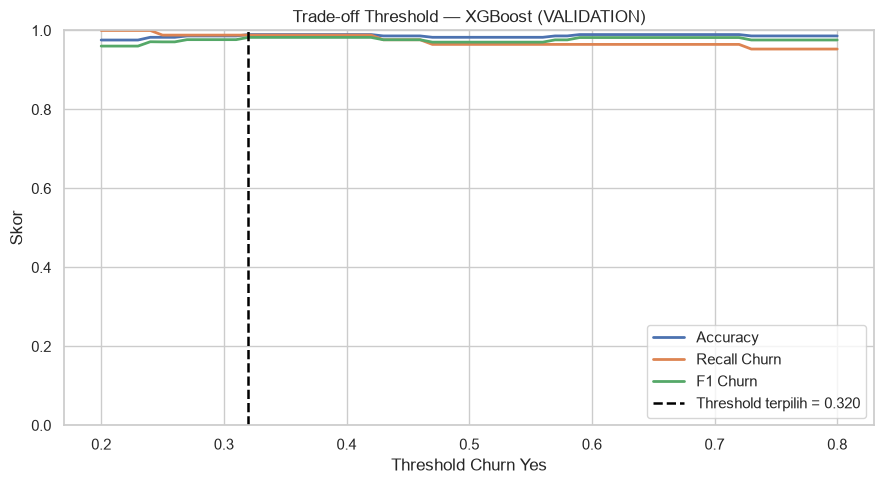

In [19]:
selected_curve = threshold_candidates[selected_model_name]
fig, ax = plt.subplots(figsize=(9, 5))
for metric in ['Accuracy','Recall Churn','F1 Churn']:
    ax.plot(selected_curve['threshold'], selected_curve[metric], lw=2, label=metric)
ax.axvline(thresholds[selected_model_name], ls='--', lw=1.8,
           color='black', label=f"Threshold terpilih = {thresholds[selected_model_name]:.3f}")
ax.set(title=f'Trade-off Threshold — {selected_model_name} (VALIDATION)',
       xlabel='Threshold Churn Yes', ylabel='Skor', ylim=(0,1))
ax.legend(); plt.tight_layout()
plt.savefig(OUT/'tradeoff_threshold_validation.png', bbox_inches='tight'); plt.show()


## 13 — Evaluasi FINAL pada test set (sekali) — ketiga model
Metrik tidak pernah digunakan untuk tuning. Keluaran wajib: Confusion Matrix tiga gambar, Classification Report, ROC-AUC, Precision, Recall, F1, accuracy.

,Accuracy,Balanced Accuracy,Precision Churn,Recall Churn,F1 Churn,ROC-AUC,Threshold
XGBoost,0.9641,0.9442,0.9794,0.8962,0.9360,0.9974,0.32
Hybrid Voting,0.9641,0.9442,0.9794,0.8962,0.9360,0.9969,0.33
Random Forest,0.9586,0.9348,0.9789,0.8774,0.9254,0.9921,0.44



Random Forest | threshold: 0.44
              precision    recall  f1-score   support

 Tidak Churn       0.95      0.99      0.97       256
       Churn       0.98      0.88      0.93       106

    accuracy                           0.96       362
   macro avg       0.97      0.93      0.95       362
weighted avg       0.96      0.96      0.96       362



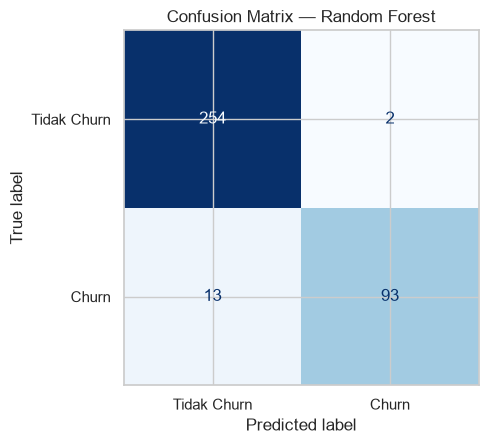


XGBoost | threshold: 0.32
              precision    recall  f1-score   support

 Tidak Churn       0.96      0.99      0.98       256
       Churn       0.98      0.90      0.94       106

    accuracy                           0.96       362
   macro avg       0.97      0.94      0.96       362
weighted avg       0.96      0.96      0.96       362



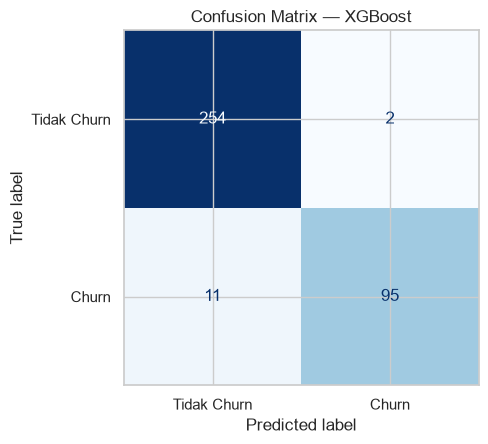


Hybrid Voting | threshold: 0.33
              precision    recall  f1-score   support

 Tidak Churn       0.96      0.99      0.98       256
       Churn       0.98      0.90      0.94       106

    accuracy                           0.96       362
   macro avg       0.97      0.94      0.96       362
weighted avg       0.96      0.96      0.96       362



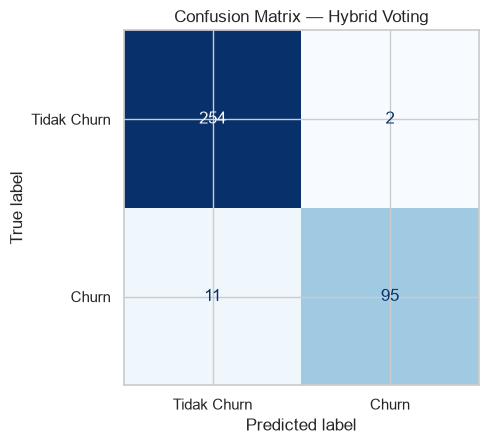

Akurasi baseline mayoritas di TEST: 70.72%
Accuracy TEST model terpilih: 96.41% | Recall churn: 89.62% | ROC-AUC: 0.9974
Selisih terhadap target 85%: -11.41 poin persentase
STATUS TARGET: TERCAPAI
PERINGATAN: set test yang sama sudah dianalisis pada notebook versi sebelumnya. Gunakan test baru/out-of-time untuk bukti final yang benar-benar independen.


In [20]:
test_stats={};test_probas={};test_preds={}
for name,model in models.items():
    p=model.predict_proba(X_test)[:,1]
    pred=(p>=thresholds[name]).astype(int)
    test_probas[name]=p;test_preds[name]=pred
    test_stats[name]={**metrics_at(y_test,p,thresholds[name]),'Threshold':thresholds[name]}
test_table=pd.DataFrame(test_stats).T.sort_values('ROC-AUC',ascending=False)
display(test_table.round(4))
for name in models:
    print('\n'+'='*55+'\n'+name+' | threshold: '+str(thresholds[name]))
    print(classification_report(y_test,test_preds[name],target_names=['Tidak Churn','Churn'],zero_division=0))
    fig,ax=plt.subplots(figsize=(5.5,4.6))
    ConfusionMatrixDisplay(confusion_matrix(y_test,test_preds[name],labels=[0,1]),
                           display_labels=['Tidak Churn','Churn']).plot(ax=ax,cmap='Blues',colorbar=False,values_format='d')
    ax.set_title('Confusion Matrix — '+name)
    plt.tight_layout();plt.savefig(OUT/f"confusion_matrix_{name.lower().replace(' ','_')}.png",bbox_inches='tight');plt.show()
print('Akurasi baseline mayoritas di TEST:',f'{(y_test==0).mean():.2%}')
acc_sel=float(test_table.loc[selected_model_name,'Accuracy'])
recall_sel=float(test_table.loc[selected_model_name,'Recall Churn'])
auc_sel=float(test_table.loc[selected_model_name,'ROC-AUC'])
print('Accuracy TEST model terpilih:',f'{acc_sel:.2%}', '| Recall churn:',f'{recall_sel:.2%}', '| ROC-AUC:',f'{auc_sel:.4f}')
print('Selisih terhadap target 85%:',f'{(TARGET_ACCURACY-acc_sel)*100:+.2f} poin persentase')
print('STATUS TARGET:', 'TERCAPAI' if acc_sel>=TARGET_ACCURACY else 'BELUM TERCAPAI — jangan klaim 85%')
print('PERINGATAN: set test yang sama sudah dianalisis pada notebook versi sebelumnya. Gunakan test baru/out-of-time untuk bukti final yang benar-benar independen.')

## 14 — Grafik ROC-AUC tiga model dalam satu gambar
Apakah Hybrid terbaik dibuktikan dengan hasil, bukan dipaksakan. Kurva semakin ke kiri-atas berarti diskriminasi semakin baik.

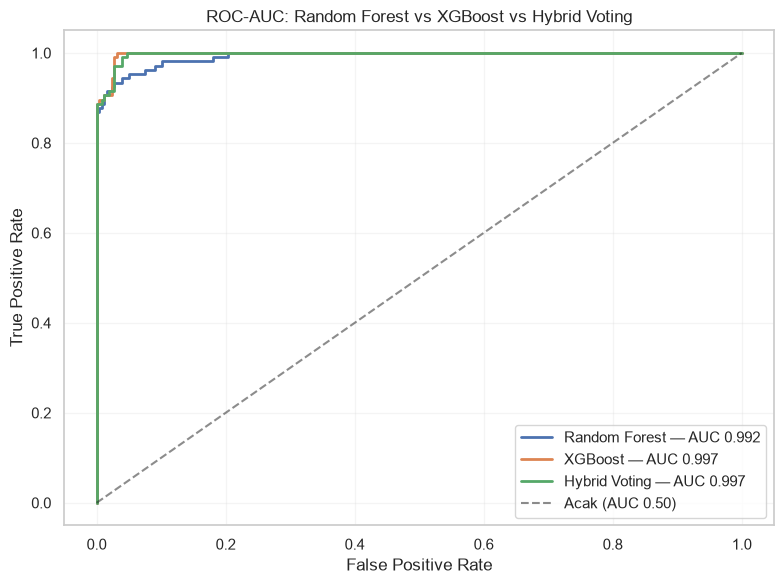

In [21]:
fig,ax=plt.subplots(figsize=(8,6))
for name,probs in test_probas.items():
    fpr,tpr,_=roc_curve(y_test,probs)
    ax.plot(fpr,tpr,lw=2,label=f'{name} — AUC {roc_auc_score(y_test,probs):.3f}')
ax.plot([0,1],[0,1],'k--',alpha=.5,label='Acak (AUC 0.50)')
ax.set(xlabel='False Positive Rate',ylabel='True Positive Rate',title='ROC-AUC: Random Forest vs XGBoost vs Hybrid Voting')
ax.legend(loc='lower right');ax.grid(alpha=.2)
plt.tight_layout();plt.savefig(OUT/'evaluasi_roc_auc_3_model.png',bbox_inches='tight');plt.show()

## 15 — Audit target leakage: pembanding TANPA `contract_status` (validation set)

**Training utama sekarang memakai `contract_status`.** Sebagai kontrol transparansi, bagian ini melatih **satu model pembanding** tanpa status kontrak dengan classifier terpilih dan parameter lain sama. Nilai model pembanding diperiksa pada **validation set**, bukan digunakan untuk memilih model lewat test set.

Jika performa dengan status jauh lebih tinggi, itu mengindikasikan ketergantungan prediksi pada informasi status, **bukan bukti kausal dan bukan bukti bahwa status tersebut tersedia sebelum churn**.

Bagian ini **tambahan audit**; ketiga model utama tetap menggunakan `contract_status`. Set `RUN_CONTRACT_DIAGNOSTIC=False` untuk melewati audit tambahan.

In [22]:
if RUN_CONTRACT_DIAGNOSTIC:
    ABLATION_CAT = [c for c in BASE_CAT if c != 'contract_status']
    ABLATION_FEATURES = BASE_NUM + ABLATION_CAT
    assert 'contract_status' in FEATURES and 'contract_status' not in ABLATION_FEATURES

    # Gunakan konfigurasi classifier dan SMOTE-Tomek TERPILIH yang sama;
    # hanya hapus satu fitur dari preprocessing model pembanding.
    pre_main = selected_model.named_steps['preprocess']
    geo_transformer = pre_main.named_transformers_.get('geo')
    geo_method = ('target' if geo_transformer is not None
                  and 'target' in getattr(geo_transformer, 'named_steps', {})
                  else 'onehot')
    ablation_model = clone(selected_model)
    ablation_model.set_params(preprocess=make_preprocessor(
        BASE_NUM, ABLATION_CAT, geo_encoding=geo_method
    ))
    ablation_model.fit(X_train[ABLATION_FEATURES], y_train)

    p_main = selected_model.predict_proba(X_val)[:, 1]
    p_no_status = ablation_model.predict_proba(X_val[ABLATION_FEATURES])[:, 1]
    leakage_audit = pd.DataFrame([
        {'Model': 'Utama DENGAN contract_status',
         'Accuracy @0.50': accuracy_score(y_val, p_main >= 0.50),
         'Recall @0.50': recall_score(y_val, p_main >= 0.50, zero_division=0),
         'ROC-AUC Validation': roc_auc_score(y_val, p_main)},
        {'Model': 'Pembanding TANPA contract_status',
         'Accuracy @0.50': accuracy_score(y_val, p_no_status >= 0.50),
         'Recall @0.50': recall_score(y_val, p_no_status >= 0.50, zero_division=0),
         'ROC-AUC Validation': roc_auc_score(y_val, p_no_status)},
    ])
    display(leakage_audit.round(4))
    leakage_audit.to_csv(OUT/'audit_ketergantungan_contract_status_validation.csv', index=False)
    print('PENTING: perbandingan pada validation hanya audit ketergantungan status, bukan validasi temporal atau bukti sebab-akibat.')
else:
    print('Audit pembanding tanpa contract_status dilewati; model utama TETAP menggunakan contract_status.')

,Model,Accuracy @0.50,Recall @0.50,ROC-AUC Validation
0,Utama DENGAN contract_status,0.9827,0.9647,0.9995
1,Pembanding TANPA contract_status,0.7059,0.3882,0.6672


PENTING: perbandingan pada validation hanya audit ketergantungan status, bukan validasi temporal atau bukti sebab-akibat.


### 15A — Bukti One-Hot Encoding `contract_status` dari TRAINING UTAMA

Sel berikut mengambil **preprocessor yang sudah ter-*fit* di model utama terpilih**, bukan encoder dari eksperimen terpisah. Kolom dummy `categorical__contract_status_...` ditunjukkan berdampingan dengan status aslinya.

Kriteria verifikasi: (1) fitur `segment` dan `contract_status` terdapat di `feature_columns`, (2) hasil One-Hot Encoder adalah 0/1, (3) ada kolom numerik `bill_avg_6m` yang melewati `StandardScaler`, dan (4) ketiga model utama mempunyai fitur `contract_status` pada preprocessornya.

In [23]:
# BUKTI ONE-HOT ENCODING DI PIPELINE TRAINING UTAMA (bukan diagnostik)
for model_name, trained_model in models.items():
    trained_pre = trained_model.named_steps['preprocess']
    trained_columns = trained_pre.get_feature_names_out().tolist()
    assert any(name.startswith('categorical__segment_') for name in trained_columns), model_name
    assert any(name.startswith('categorical__contract_status_') for name in trained_columns), model_name
    assert 'numeric__bill_avg_6m' in trained_columns, model_name
    numeric_pipe = trained_pre.named_transformers_['numeric']
    assert isinstance(numeric_pipe.named_steps['scaler'], StandardScaler), model_name
    categorical_pipe = trained_pre.named_transformers_['categorical']
    assert isinstance(categorical_pipe.named_steps['onehot'], OneHotEncoder), model_name
    print(f'VALIDASI {model_name}: segment + contract_status = One-Hot; bill_avg_6m = StandardScaler')

pre_main = selected_model.named_steps['preprocess']
encoded_names = pre_main.get_feature_names_out().tolist()
status_indices = [i for i, name in enumerate(encoded_names)
                  if name.startswith('categorical__contract_status_')]
status_cols = [encoded_names[i] for i in status_indices]
assert status_cols, 'Hasil One-Hot contract_status tidak ditemukan pada model terpilih!'

examples = (X_train[['segment', 'contract_status']]
            .groupby('contract_status', dropna=False, group_keys=False)
            .head(2).copy())
encoded_examples = pre_main.transform(X_train.loc[examples.index])
encoded_status = pd.DataFrame(
    np.asarray(encoded_examples)[:, status_indices],
    index=examples.index, columns=status_cols
).astype(int)
proof = pd.concat([examples, encoded_status], axis=1).reset_index(drop=True)
print('BUKTI One-Hot Encoding dari model utama:', selected_model_name)
display(proof)
print('Kolom dummy contract_status:', status_cols)
assert encoded_status.isin([0, 1]).all().all(), 'One-Hot Encoding tidak biner.'
assert (encoded_status.sum(axis=1) == 1).all(), 'Setiap baris diharapkan memiliki satu kategori aktif.'
print('VERIFIKASI LULUS: contract_status digunakan dalam training utama semua model.')
print('PERINGATAN: Terminated dapat menyebabkan target leakage; periksa waktu pencatatan untuk klaim prediksi dini.')

VALIDASI Random Forest: segment + contract_status = One-Hot; bill_avg_6m = StandardScaler
VALIDASI XGBoost: segment + contract_status = One-Hot; bill_avg_6m = StandardScaler
VALIDASI Hybrid Voting: segment + contract_status = One-Hot; bill_avg_6m = StandardScaler
BUKTI One-Hot Encoding dari model utama: XGBoost


,segment,contract_status,categorical__contract_status_Active,categorical__contract_status_Expiring Soon,categorical__contract_status_Terminated,categorical__contract_status_Under Renewal
0,CONSTRUCTION & ENGINEERING,Active,1,0,0,0
1,HEALTHCARE,Terminated,0,0,1,0
2,OTHERS (ONE TIME),Terminated,0,0,1,0
3,CONSTRUCTION & ENGINEERING,Active,1,0,0,0
4,OTHERS (ONE TIME),Under Renewal,0,0,0,1
5,CONSTRUCTION & ENGINEERING,Expiring Soon,0,1,0,0
6,OTHERS (ONE TIME),Expiring Soon,0,1,0,0
7,CONSTRUCTION & ENGINEERING,Under Renewal,0,0,0,1


Kolom dummy contract_status: ['categorical__contract_status_Active', 'categorical__contract_status_Expiring Soon', 'categorical__contract_status_Terminated', 'categorical__contract_status_Under Renewal']
VERIFIKASI LULUS: contract_status digunakan dalam training utama semua model.
PERINGATAN: Terminated dapat menyebabkan target leakage; periksa waktu pencatatan untuk klaim prediksi dini.


### 15B — Analisis keterbatasan dan integritas evaluasi

Notebook sekarang **memasukkan `contract_status` ke training utama** agar tahapan preprocessing memenuhi instruksi dosen secara harfiah. Metrik yang dihasilkan menjelaskan kemampuan klasifikasi pada data dengan status kontrak yang sudah dicatat.

**Risiko metodologis:** jika status `Terminated` baru muncul setelah churn, maka skor ROC-AUC atau accuracy tinggi tidak menunjukkan kemampuan *early warning*. Audit di atas dapat memperlihatkan besar ketergantungan terhadap status, tetapi tidak memperbaiki persoalan ketersediaan fitur pada waktu prediksi.

Untuk penelitian prediksi churn sebelum kejadian, solusi yang lebih sah adalah data kontrak **sebelum churn**, pencatatan waktu kejadian, validasi temporal, atau model pembanding tanpa status. Test set yang sama telah dilihat dalam iterasi sebelumnya; jangan diklaim sebagai test buta baru.

In [24]:
# Ringkasan perbandingan terhadap baseline dan target (evaluasi internal).
majority_baseline = float((y_test == 0).mean())
comparison = test_table[['Accuracy','Recall Churn','F1 Churn','ROC-AUC','Threshold']].copy()
comparison['Selisih vs baseline (pp)'] = 100 * (comparison['Accuracy'] - majority_baseline)
comparison['Jarak ke 85% (pp)'] = 100 * (TARGET_ACCURACY - comparison['Accuracy'])
display(comparison.round(4))
print('Baseline selalu NO:',f'{majority_baseline:.2%}',
      '| Target penelitian:',f'{TARGET_ACCURACY:.0%}')
print('Model utama menggunakan contract_status, tetapi TIDAK menggunakan Cust. ID sebagai prediktor.')
assert 'Cust. ID' not in FEATURES and 'contract_status' in FEATURES
print('PERINGATAN: periksa kapan Terminated tercatat sebelum menafsirkan metrik sebagai prediksi churn sebelum kejadian.')


,Accuracy,Recall Churn,F1 Churn,ROC-AUC,Threshold,Selisih vs baseline (pp),Jarak ke 85% (pp)
XGBoost,0.9641,0.8962,0.9360,0.9974,0.32,25.6906,-11.4088
Hybrid Voting,0.9641,0.8962,0.9360,0.9969,0.33,25.6906,-11.4088
Random Forest,0.9586,0.8774,0.9254,0.9921,0.44,25.1381,-10.8564


Baseline selalu NO: 70.72% | Target penelitian: 85%
Model utama menggunakan contract_status, tetapi TIDAK menggunakan Cust. ID sebagai prediktor.
PERINGATAN: periksa kapan Terminated tercatat sebelum menafsirkan metrik sebagai prediksi churn sebelum kejadian.


## 16 — Interpretabilitas SHAP Hybrid Voting: Summary, Beeswarm, Waterfall
Permutasi SHAP menjelaskan **probabilitas keluaran Hybrid Voting**. Karena memakai One-Hot Encoding, perhitungan dilakukan pada fitur numerik yang sudah di-encode. **SHAP bukan bukti kausalitas**. Jika Colab lambat, turunkan `SHAP_EXPLAIN_N` ke 4.

In [25]:
hybrid_model=models['Hybrid Voting']
pre=hybrid_model.named_steps['preprocess']
enc_names=list(pre.get_feature_names_out())
bg=X_train.sample(n=min(SHAP_BACKGROUND_N,len(X_train)),random_state=SEED)
xe=X_test.sample(n=min(SHAP_EXPLAIN_N,len(X_test)),random_state=SEED)
bg_enc=pd.DataFrame(pre.transform(bg),columns=enc_names,index=bg.index)
xe_enc=pd.DataFrame(pre.transform(xe),columns=enc_names,index=xe.index)

def positive_hybrid(m):
    return hybrid_model.named_steps['classifier'].predict_proba(np.asarray(m))[:,1]

shap_exp=shap.Explainer(positive_hybrid,shap.maskers.Independent(bg_enc),algorithm='permutation')
sv=shap_exp(xe_enc,max_evals=2*len(enc_names)+1)
pretty=[s.replace('numeric__','').replace('categorical__','').replace('segment_','Sektor: ')
          .replace('usage_trend_','Tren: ').replace('has_competitor_','Kompetitor: ')
          .replace('contract_status_','Kontrak: ').replace('City_','Kota: ').replace('State/Prov_','Prov: ').replace('geo__','Lokasi: ') for s in enc_names]
disp=xe_enc.to_numpy().copy()
for col in BASE_NUM:
    disp[:,enc_names.index('numeric__'+col)] = xe[col].to_numpy()
sv.feature_names=pretty;sv.data=disp
x_display=pd.DataFrame(disp,columns=pretty,index=xe.index)
print('SHAP dihitung untuk',len(xe),'pelanggan dan',len(enc_names),'fitur encoded (model Hybrid Voting).')

PermutationExplainer explainer: 33it [00:12,  2.06it/s]                        

SHAP dihitung untuk 32 pelanggan dan 34 fitur encoded (model Hybrid Voting).


C:\Users\outlo\AppData\Local\Temp\ipykernel_12396\773875204.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv.values,x_display,feature_names=pretty,show=False,max_display=17)


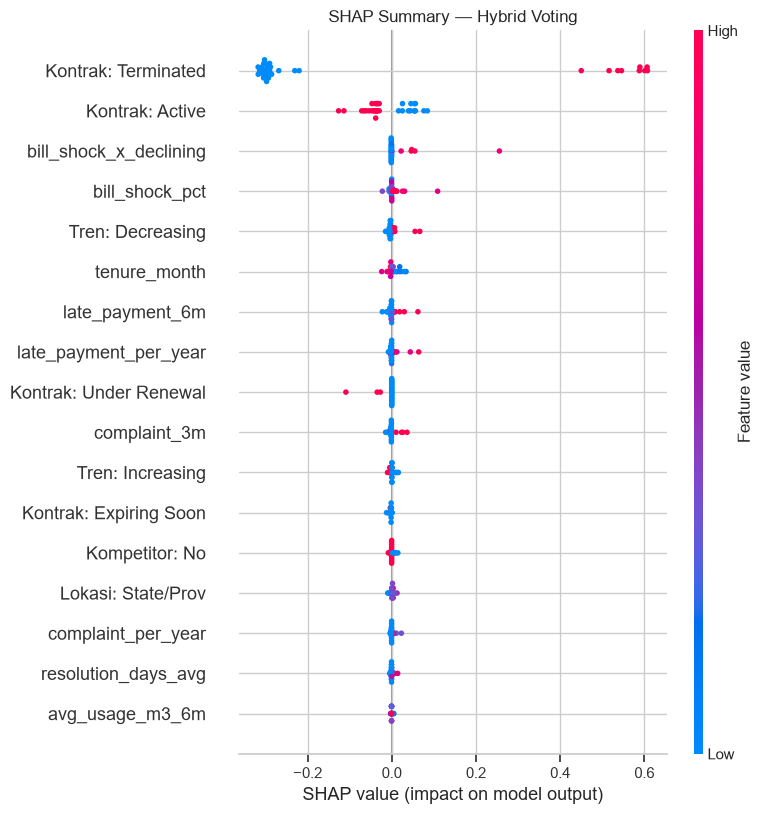

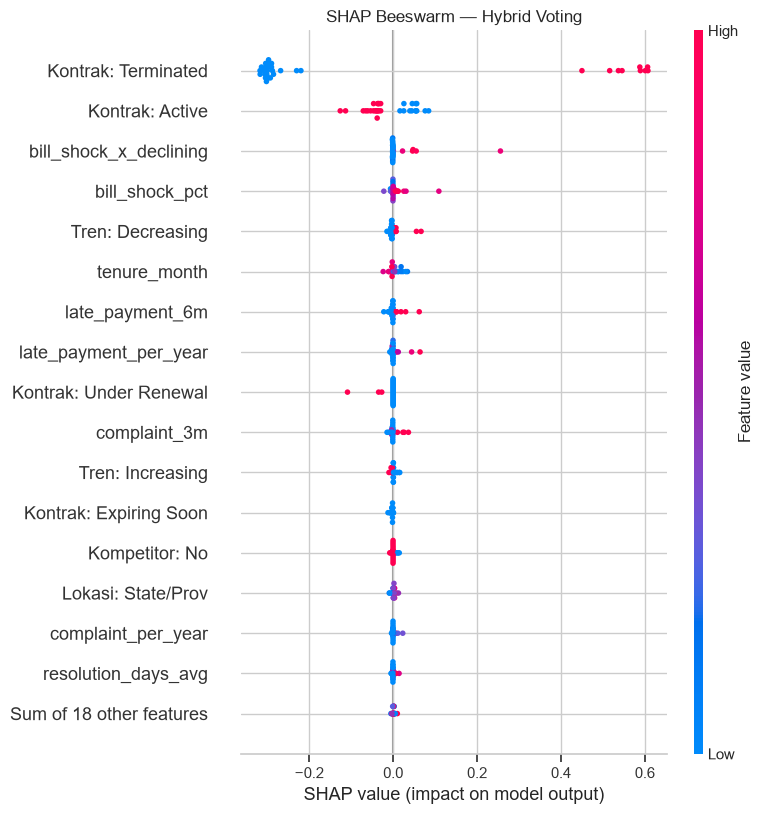

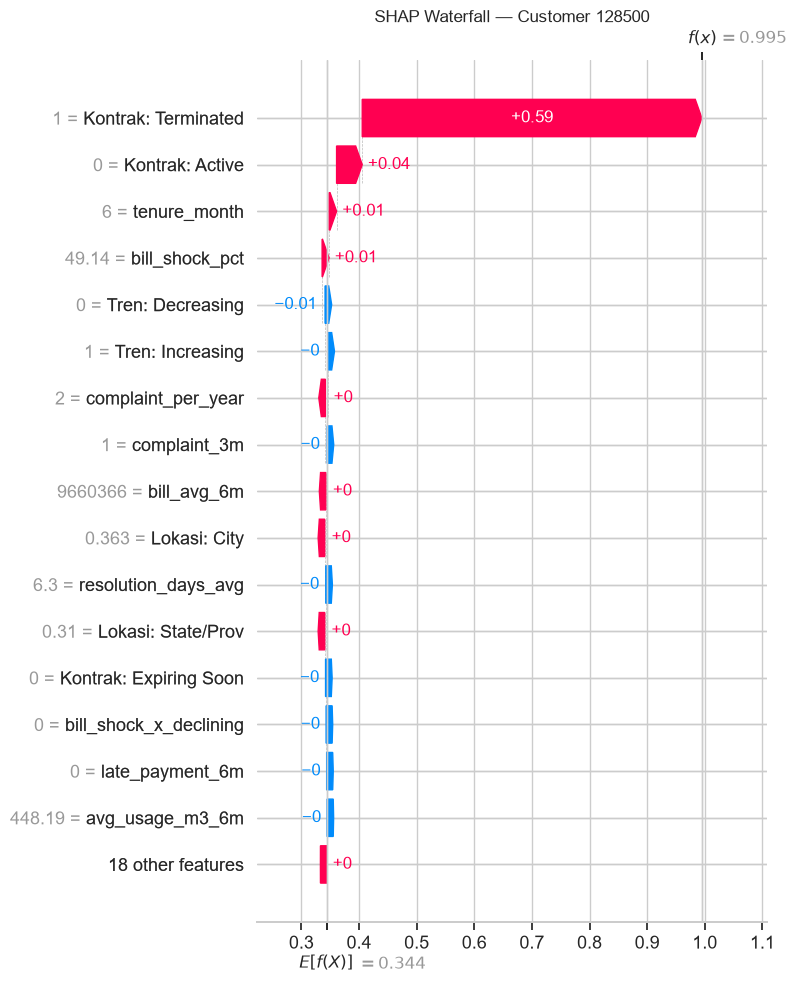

Pelanggan SHAP: 128500 | Probabilitas Churn Hybrid: 99.5%


In [26]:
shap.summary_plot(sv.values,x_display,feature_names=pretty,show=False,max_display=17)
plt.title('SHAP Summary — Hybrid Voting');plt.tight_layout()
plt.savefig(OUT/'shap_summary_hybrid.png',bbox_inches='tight');plt.show()
shap.plots.beeswarm(sv,max_display=17,show=False)
plt.title('SHAP Beeswarm — Hybrid Voting');plt.tight_layout()
plt.savefig(OUT/'shap_beeswarm_hybrid.png',bbox_inches='tight');plt.show()
chosen_i=0
customer_id=df.loc[xe.index[chosen_i],'Cust. ID']
shap.plots.waterfall(sv[chosen_i],max_display=17,show=False)
plt.title('SHAP Waterfall — Customer '+str(customer_id));plt.tight_layout()
plt.savefig(OUT/'shap_waterfall_hybrid.png',bbox_inches='tight');plt.show()
print('Pelanggan SHAP:',customer_id,'| Probabilitas Churn Hybrid:',f"{hybrid_model.predict_proba(xe.iloc[[chosen_i]])[0,1]:.1%}")

### 16A — SHAP untuk model terbaik yang akan diekspor

SHAP sebelumnya menjelaskan **Hybrid Voting** sebagaimana diminta judul. Karena model terpilih berdasarkan ROC-AUC validasi dapat berupa XGBoost atau Random Forest, plot berikut juga menjelaskan **model yang benar-benar digunakan dashboard**. Hasilnya tidak boleh diganti dengan interpretasi model lain; SHAP menjelaskan prediksi dan bukan kausalitas.


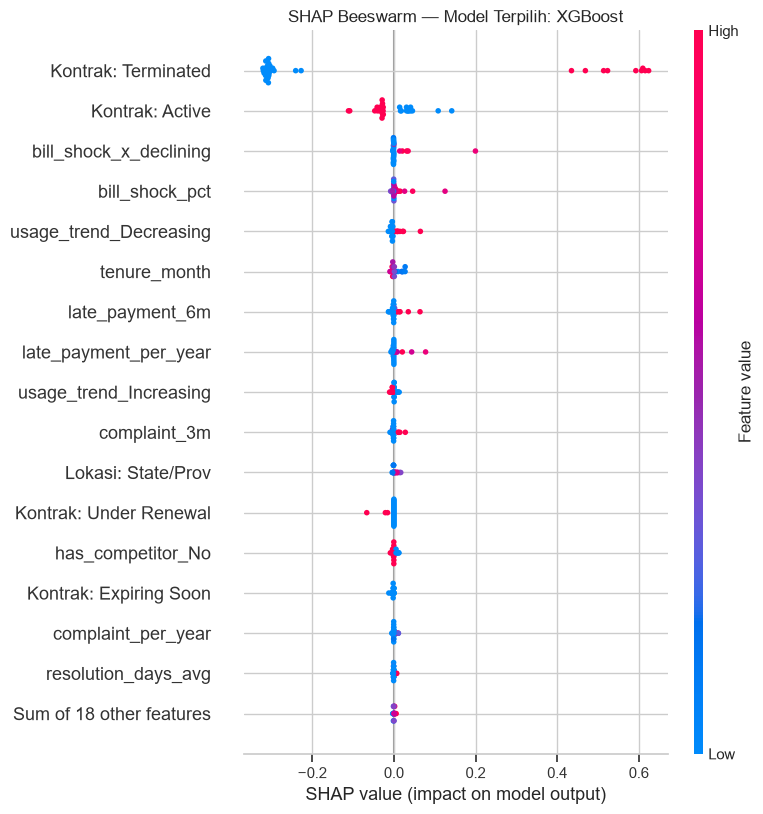

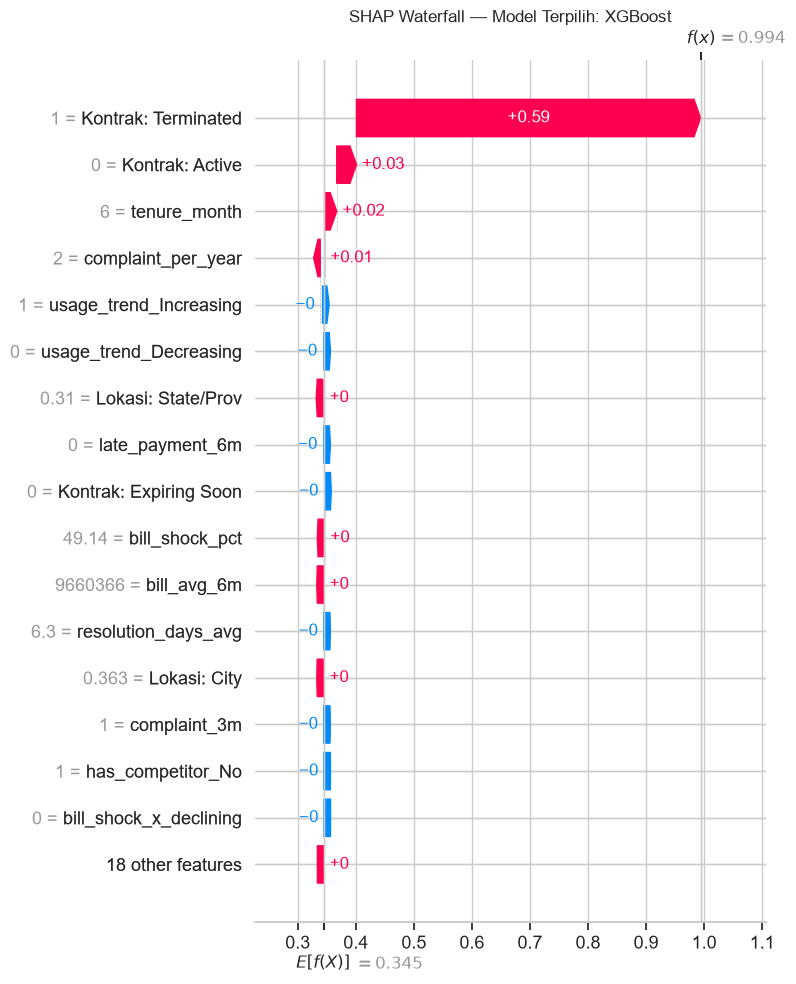

Penjelasan model dashboard: XGBoost | 32 pelanggan yang sama dengan SHAP Hybrid.


In [27]:
# Gunakan sampel penjelasan yang sama untuk melihat perbedaan Hybrid vs model terpilih.
best_pre=selected_model.named_steps['preprocess']
best_names=list(best_pre.get_feature_names_out())
best_bg=pd.DataFrame(best_pre.transform(bg),columns=best_names,index=bg.index)
best_xe=pd.DataFrame(best_pre.transform(xe),columns=best_names,index=xe.index)

def best_probability(m):
    return selected_model.named_steps['classifier'].predict_proba(np.asarray(m))[:,1]

best_explainer=shap.Explainer(best_probability,shap.maskers.Independent(best_bg),algorithm='permutation')
sv_best=best_explainer(best_xe,max_evals=2*len(best_names)+1)
best_pretty=[s.replace('numeric__','').replace('categorical__','')
               .replace('segment_','Sektor: ').replace('contract_status_','Kontrak: ').replace('City_','Kota: ')
               .replace('State/Prov_','Prov: ').replace('geo__','Lokasi: ') for s in best_names]
best_disp=best_xe.to_numpy().copy()
for c in BASE_NUM:
    best_disp[:,best_names.index('numeric__'+c)]=xe[c].to_numpy()
sv_best.feature_names=best_pretty
sv_best.data=best_disp
shap.plots.beeswarm(sv_best,max_display=17,show=False)
plt.title('SHAP Beeswarm — Model Terpilih: '+selected_model_name)
plt.tight_layout();plt.savefig(OUT/'shap_beeswarm_model_terpilih.png',bbox_inches='tight');plt.show()
shap.plots.waterfall(sv_best[0],max_display=17,show=False)
plt.title('SHAP Waterfall — Model Terpilih: '+selected_model_name)
plt.tight_layout();plt.savefig(OUT/'shap_waterfall_model_terpilih.png',bbox_inches='tight');plt.show()
print('Penjelasan model dashboard:',selected_model_name, '|',len(xe),'pelanggan yang sama dengan SHAP Hybrid.')


## 17 — Kategori risiko dan prioritas retensi pelanggan pada TEST

**HIGH RISK = Churn Yes** dan **LOW RISK = Churn No**, keduanya memakai **threshold model terpilih yang sama** (hasil validation tuning). Tidak ada MEDIUM RISK. Kebijakan ini praktis, tetapi HIGH/LOW merupakan label dari keputusan biner, bukan segmentasi risiko independen yang telah dikalibrasi. Rekomendasi retensi berupa aturan bisnis awal, **bukan bukti kausal SHAP**.


In [28]:
# Satu sumber threshold untuk prediksi Churn Yes/No dan HIGH/LOW RISK.
selected_threshold = float(thresholds[selected_model_name])

def risk_level(p, threshold=selected_threshold):
    return 'HIGH RISK' if p >= threshold else 'LOW RISK'

def recommendation(r):
    if r['risk_level'] == 'HIGH RISK':
        return 'Rekomendasi: Service Recovery - Telepon dalam 24 jam'
    return 'Aman'

table = df.loc[X_test.index, ['Cust. ID','complaint_3m','bill_shock_pct','contract_status']].copy()
table['prob_churn'] = selected_model.predict_proba(X_test)[:,1]
table['prediksi_churn'] = np.where(table['prob_churn'] >= selected_threshold, 'Yes', 'No')
table['risk_level'] = table['prob_churn'].map(risk_level)
table['rekomendasi'] = table.apply(recommendation, axis=1)
table = table.sort_values('prob_churn', ascending=False)
assert (table['risk_level'].eq('HIGH RISK') == table['prediksi_churn'].eq('Yes')).all()
display(table[['Cust. ID','prob_churn','prediksi_churn','risk_level','rekomendasi']].head(15))
table.to_csv(OUT/'prioritas_retensi_test.csv', index=False)


,Cust. ID,prob_churn,prediksi_churn,risk_level,rekomendasi
992,124917,0.998188,Yes,HIGH RISK,Rekomendasi: Service Recovery - Telepon dalam ...
1078,117388,0.998168,Yes,HIGH RISK,Rekomendasi: Service Recovery - Telepon dalam ...
949,124973,0.998049,Yes,HIGH RISK,Rekomendasi: Service Recovery - Telepon dalam ...
975,125065,0.997986,Yes,HIGH RISK,Rekomendasi: Service Recovery - Telepon dalam ...
36,165141,0.997982,Yes,HIGH RISK,Rekomendasi: Service Recovery - Telepon dalam ...
1013,120929,0.997979,Yes,HIGH RISK,Rekomendasi: Service Recovery - Telepon dalam ...
982,125206,0.997949,Yes,HIGH RISK,Rekomendasi: Service Recovery - Telepon dalam ...
780,128305,0.997914,Yes,HIGH RISK,Rekomendasi: Service Recovery - Telepon dalam ...
712,113559,0.997899,Yes,HIGH RISK,Rekomendasi: Service Recovery - Telepon dalam ...
351,165131,0.997774,Yes,HIGH RISK,Rekomendasi: Service Recovery - Telepon dalam ...


## 18 — Simpan model terbaik, Hybrid Voting, dan metadata threshold

`model_hybrid.pkl` (nama file sesuai persyaratan) menyimpan model yang dipilih berdasarkan **validation set**, yang dapat berupa XGBoost, Random Forest, atau Hybrid Voting. `hybrid_voting.pkl` menyimpan model Hybrid sebenarnya.

Metadata akan menyatakan **`used_contract_status=True`** dan mencantumkan risiko kebocoran target. Dashboard membaca fitur yang sama, termasuk `contract_status`, dan threshold keputusan terbaru dari `model_metadata.json`. Angka 52,5% **tidak** ditulis permanen.

In [29]:
MODEL_FILE = Path('model_hybrid.pkl')
META_FILE = Path('model_metadata.json')
joblib.dump(selected_model, MODEL_FILE)
HYBRID_FILE = Path('hybrid_voting.pkl')
joblib.dump(models['Hybrid Voting'], HYBRID_FILE)
meta = {
    'project': 'Churn Industri Gas Alam — Training Utama One-Hot segment + contract_status dan SMOTE-Tomek',
    'dataset_sheet': SHEET,
    'total_rows': len(df),
    'trained_rows': len(X_train), 'training_rows': len(X_train),
    'validation_rows': len(X_val), 'test_rows': len(X_test),
    'selected_model': selected_model_name,
    'selection_metric': 'Accuracy validation dengan batas minimum recall churn',
    'selection_auc': float(val_table.loc[selected_model_name,'ROC-AUC']),
    'selection_validation_accuracy': float(val_table.loc[selected_model_name,'Accuracy']),
    'target_accuracy_aspirational': TARGET_ACCURACY,
    'accuracy_target_achieved_on_test': bool(test_table.loc[selected_model_name,'Accuracy'] >= TARGET_ACCURACY),
    'test_auc_selected_model': float(test_table.loc[selected_model_name,'ROC-AUC']),
    'test_accuracy_selected_model': float(test_table.loc[selected_model_name,'Accuracy']),
    'test_recall_churn_selected_model': float(test_table.loc[selected_model_name,'Recall Churn']),
    'decision_threshold': float(thresholds[selected_model_name]),
    'risk_policy': 'binary_same_as_decision_threshold',
    'risk_labels': ['HIGH RISK', 'LOW RISK'],
    'all_model_thresholds': {k:float(v) for k,v in thresholds.items()},
    'feature_columns': FEATURES,
    'numeric_features': BASE_NUM,
    'categorical_features': BASE_CAT,
    'used_contract_status': True,
    'used_location_features': INCLUDE_LOCATION,
    'hybrid_weights': [int(W_RF), int(W_XGB)],
    'hybrid_smote_ratio': float(hybrid_sampling_ratio),
    'preprocessor_location_policy': 'Cross-fitted TargetEncoder or OneHotEncoder chosen by CV on TRAIN only',
    'final_test_reused_for_iterative_comparison': True,
    'cv_folds': CV_FOLDS,
    'tuning_iterations': TUNING_ITERATIONS,
    'tuning_objective': TUNING_OBJECTIVE,
    'min_validation_recall': MIN_VALIDATION_RECALL,
    'seed': SEED,
    'cautions': [
        'contract_status is included in all primary models. Terminated can reflect churn that already occurred; metrics are not evidence of prospective prediction without timestamp verification.',
        'Probabilities uncalibrated; SHAP is not causal.',
        'Model training uses SMOTE-Tomek only on training data.',
        'Risk HIGH/LOW is a relabeling of binary Churn Yes/No, not an independent risk segmentation.',
        'SMOTE after one-hot encoding may interpolate categorical dummy variables.',
        'Test split has been examined in prior notebook, so this is not a fully blind final test.',
        'Accuracy target 85 percent is aspirational; do not report without measured evidence.',
    ],
}
META_FILE.write_text(json.dumps(meta,indent=2,ensure_ascii=False),encoding='utf-8')
loaded = joblib.load(MODEL_FILE)
assert np.allclose(loaded.predict_proba(X_test.iloc[:5]), selected_model.predict_proba(X_test.iloc[:5]))
assert meta['risk_policy'] == 'binary_same_as_decision_threshold'
assert meta['used_contract_status'] is True
assert 'contract_status' in meta['feature_columns']
print('Model diekspor:', MODEL_FILE.resolve(), '| Isi:', selected_model_name)
print('Metadata:', META_FILE.resolve(), '| Threshold:', f'{meta["decision_threshold"]:.1%}')
assert isinstance(joblib.load(HYBRID_FILE).named_steps['classifier'], VotingClassifier)
print('Model Hybrid Voting asli juga tersedia:', HYBRID_FILE.resolve())


Model diekspor: C:\Users\outlo\OneDrive\Desktop\c_niaa\261005\model_hybrid.pkl | Isi: XGBoost
Metadata: C:\Users\outlo\OneDrive\Desktop\c_niaa\261005\model_metadata.json | Threshold: 32.0%
Model Hybrid Voting asli juga tersedia: C:\Users\outlo\OneDrive\Desktop\c_niaa\261005\hybrid_voting.pkl


## 19 — Ekspor model dan dashboard opsional (lokal)

File `app.py` untuk Streamlit **opsional** dan sudah disertakan di folder proyek. Setelah training selesai, `model_hybrid.pkl`, `hybrid_voting.pkl`, `model_metadata.json`, grafik, dan ringkasan retensi tersedia di folder lokal. Notebook juga membuat ZIP keluaran, tanpa otomatis mengunduh apa pun.


### 19A — Menulis `app.py` yang konsisten dengan kategori HIGH / LOW serta encoding pilihan CV

Menjalankan sel berikut membuat ulang `app.py` dengan layout tiga kolom, dropdown ID, probabilitas Churn Yes, prediksi Yes/No, SHAP Waterfall, dan rekomendasi retensi. **Tidak ada MEDIUM RISK.** Aturan risiko selalu mengikuti `decision_threshold` terbaru dari `model_metadata.json`, bukan angka 40%/70% maupun 52,5% yang ditulis permanen.


In [30]:
# Pembuatan app.py: rekomendasi retensi hanya HIGH RISK atau Aman.
APP_SOURCE = '"""Dashboard prediksi churn industri gas alam (jalankan: streamlit run app.py)."""\nfrom __future__ import annotations\n\nimport json\nfrom pathlib import Path\n\nimport joblib\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport shap\nimport streamlit as st\n\nst.set_page_config(page_title="Gas Alam | Customer Churn", page_icon="", layout="wide")\n\nROOT = Path(__file__).resolve().parent\nMODEL_PATH = ROOT / "model_hybrid.pkl"\nMETA_PATH = ROOT / "model_metadata.json"\nDATA_PATH = ROOT / "dataset.xlsx"\n\n\n@st.cache_resource(show_spinner=False)\ndef load_model_and_metadata():\n    model = joblib.load(MODEL_PATH)\n    meta = json.loads(META_PATH.read_text(encoding="utf-8"))\n    return model, meta\n\n\n@st.cache_data(show_spinner=False)\ndef load_customers():\n    raw = pd.read_excel(DATA_PATH, sheet_name="Master Customer Data", engine="openpyxl")\n    d = raw.copy()\n    d.columns = d.columns.astype(str).str.strip()\n    d["Cust. ID"] = d["Cust. ID"].astype(str).str.strip()\n    d["segment"] = d["Industry Class Type"]\n    for c in ["tenure_month", "avg_usage_m3_6m", "bill_avg_6m", "bill_shock_pct",\n              "late_payment_6m", "complaint_3m", "resolution_days_avg"]:\n        d[c] = pd.to_numeric(d[c], errors="coerce")\n    for c in ["segment", "usage_trend", "has_competitor", "contract_status", "City", "State/Prov"]:\n        d[c] = d[c].map(lambda v: v.strip() if isinstance(v, str) else np.nan)\n        d[c] = d[c].replace("", np.nan)\n    # Engineered features MUST use the same deterministic formula as the Colab notebook.\n    tenure_safe = d["tenure_month"].clip(lower=1)\n    d["complaint_per_year"] = d["complaint_3m"] * 12 / tenure_safe\n    d["late_payment_per_year"] = d["late_payment_6m"] * 12 / tenure_safe\n    d["bill_shock_x_declining"] = d["bill_shock_pct"] * d["usage_trend"].eq("Decreasing").astype(float)\n    d = d.drop_duplicates(subset=["Cust. ID"], keep="first").reset_index(drop=True)\n    return d\n\n\ndef classify_churn(probability: float, decision_threshold: float) -> tuple[str, str, str]:\n    """Prediksi Yes/No dan kategori risiko memakai threshold model yang sama.\n\n    Threshold ditentukan saat evaluasi model di notebook, lalu disimpan di\n    model_metadata.json; Streamlit hanya membaca dan menerapkannya.\n    """\n    if probability >= decision_threshold:\n        return "Yes", "HIGH RISK", "🔴"\n    return "No", "LOW RISK", "🟢"\n\n\ndef format_churn_probability(probability: float) -> str:\n    """Tampilkan skor kecil tanpa membulatkan nilai nonnol menjadi 0,0%."""\n    percent = probability * 100\n    if probability == 0.0:\n        return "0%"  # Nol benar-benar berasal dari output numerik model.\n    if percent < 0.0001:\n        return "< 0,0001%"\n    if percent < 1:\n        return f"{percent:.4f}%".replace(".", ",")\n    return f"{percent:.2f}%".replace(".", ",")\n\n\ndef get_churn_yes_probability(model, customer_frame: pd.DataFrame) -> tuple[float, int]:\n    """Ambil kelas Churn=1 secara eksplisit; bukan mengasumsikan kolom ke-2."""\n    classes = np.asarray(model.classes_)\n    indices = np.flatnonzero(classes == 1)\n    if len(indices) != 1:\n        raise ValueError(f"Model tidak memiliki kelas Churn=1. Kelas ditemukan: {classes.tolist()}")\n    yes_index = int(indices[0])\n    result = np.asarray(model.predict_proba(customer_frame), dtype=float)\n    if result.ndim != 2 or result.shape[0] != 1 or yes_index >= result.shape[1]:\n        raise ValueError("Bentuk hasil predict_proba tidak sesuai.")\n    probability = float(result[0, yes_index])\n    if not np.isfinite(probability) or not 0 <= probability <= 1:\n        raise ValueError(f"Skor probabilitas tidak valid: {probability}")\n    return probability, yes_index\n\n\ndef recommend_actions(risk_label: str) -> str:\n    """Rekomendasi sederhana berdasarkan kategori risiko hasil prediksi."""\n    if risk_label == "HIGH RISK":\n        return "Rekomendasi: Service Recovery - Telepon dalam 24 jam"\n    return "Aman"\n\n\n@st.cache_resource(show_spinner=False)\ndef make_shap_explainer(_model, feature_names: tuple, _background, yes_index: int):\n    """SHAP pada fitur numerik yang telah di-encode oleh pipeline terlatih."""\n    def probability_positive(values):\n        return _model.named_steps["classifier"].predict_proba(np.asarray(values))[:, yes_index]\n\n    return shap.Explainer(\n        probability_positive,\n        shap.maskers.Independent(_background),\n        algorithm="permutation",\n    )\n\n\nst.title("Dashboard Customer Churn — Industri Gas Alam")\nst.caption("Prediksi berbasis model Machine Learning + penjelasan SHAP + rekomendasi retensi")\n\nmissing = [p.name for p in [MODEL_PATH, META_PATH, DATA_PATH] if not p.exists()]\nif missing:\n    st.error("Berkas belum tersedia: " + ", ".join(missing))\n    st.info("Jalankan notebook Colab sampai tahap Save Model, lalu tempatkan berkas di folder yang sama dengan app.py.")\n    st.stop()\n\ntry:\n    model, metadata = load_model_and_metadata()\n    df = load_customers()\nexcept Exception as exc:\n    st.error(f"Gagal memuat model/data: {exc}")\n    st.stop()\n\nfeatures = metadata["feature_columns"]\nnumeric = metadata["numeric_features"]\nmissing_columns = sorted(set(features) - set(df.columns))\nif missing_columns:\n    st.error(f"Kolom input tidak ditemukan: {missing_columns}")\n    st.stop()\n\nst.info(\n    f"Model terpilih: **{metadata[\'selected_model\']}** | "\n    f"AUC test: **{metadata[\'test_auc_selected_model\']:.3f}** | "\n    f"Accuracy test: **{metadata.get(\'test_accuracy_selected_model\', float(\'nan\')):.1%}** | "\n    f"Training: **{metadata[\'trained_rows\']:,} pelanggan**"\n)\nleft, center, right = st.columns([1.05, 1.65, 1.35], gap="large")\n\nwith left:\n    st.subheader("1 · Pilih Pelanggan")\n    selected_id = st.selectbox("ID Pelanggan", options=df["Cust. ID"].tolist(), index=0)\n    customer = df.loc[df["Cust. ID"] == selected_id].iloc[0]\n    st.text(f"Kota: {customer.get(\'City\', \'-\')}")\n    st.text(f"Segment: {customer.get(\'segment\', \'-\')}")\n    st.text(f"Status kontrak: {customer.get(\'contract_status\', \'-\')}")\n    st.metric("Tenure", f"{customer[\'tenure_month\']:.0f} bulan")\n    st.metric("Keluhan 3 bulan", f"{customer[\'complaint_3m\']:.0f}")\n    st.metric("Perubahan tagihan", f"{customer[\'bill_shock_pct\']:+.1f}%")\n\nX_selected = pd.DataFrame([customer[features].to_dict()], columns=features)\ntry:\n    prob, yes_index = get_churn_yes_probability(model, X_selected)\n    decision_threshold = float(metadata["decision_threshold"])\n    if not (np.isfinite(decision_threshold) and 0 < decision_threshold < 1):\n        raise ValueError("decision_threshold harus berada di antara 0 dan 1.")\nexcept Exception as exc:\n    st.error(f"Gagal menghitung probabilitas atau membaca threshold model: {exc}")\n    st.stop()\nchurn_prediction, risk_label, risk_icon = classify_churn(prob, decision_threshold)\n\nwith center:\n    st.subheader("2 · Prediksi & Penjelasan")\n    st.metric("Prediksi Churn (Yes/No)", churn_prediction)\n    st.metric("Probabilitas Churn Yes (skor model)", format_churn_probability(prob))\n    st.progress(max(0.0, min(prob, 1.0)))\n    st.markdown(f"### {risk_icon} {risk_label}")\n    if prob == 0.0:\n        st.info("Model mengembalikan probabilitas tepat 0 pada presisi numerik yang tersedia. "\n                "Tampilan ini bukan kesalahan pembulatan; tinjau fitur dan validitas model bila hasil terasa tidak wajar.")\n    elif prob * 100 < 0.05:\n        st.caption("Skor churn sangat kecil tetapi **bukan nol**. Angka utama ditampilkan dengan presisi tambahan agar tidak tampak sebagai 0%.")\n    st.caption(\n        f"Batas prediksi dan kategori risiko: {decision_threshold:.1%}.  \\n"\n        f"Skor ≥ {decision_threshold:.1%} = Churn Yes / HIGH RISK;  \\n"\n        f"skor < {decision_threshold:.1%} = Churn No / LOW RISK."\n    )\n    st.markdown("**SHAP Waterfall — Faktor yang berkontribusi terhadap prediksi**")\n    if st.checkbox("Tampilkan SHAP Waterfall", value=True):\n        with st.spinner("Menghitung kontribusi SHAP untuk pelanggan terpilih..."):\n            preprocessor = model.named_steps["preprocess"]\n            encoded_names = list(preprocessor.get_feature_names_out())\n            background = df[features].sample(n=min(12, len(df)), random_state=42)\n            background_encoded = pd.DataFrame(\n                preprocessor.transform(background), columns=encoded_names\n            )\n            selected_encoded = pd.DataFrame(\n                preprocessor.transform(X_selected), columns=encoded_names\n            )\n            explainer = make_shap_explainer(model, tuple(encoded_names), background_encoded, yes_index)\n            explanation = explainer(selected_encoded, max_evals=2 * len(encoded_names) + 1)\n            pretty_names = [\n                name.replace("numeric__", "").replace("categorical__", "")\n                    .replace("segment_", "Sektor: ").replace("usage_trend_", "Tren: ")\n                    .replace("has_competitor_", "Kompetitor: ").replace("contract_status_", "Kontrak: ")\n                    .replace("City_", "Kota: ").replace("State/Prov_", "Provinsi: ")\n                for name in encoded_names\n            ]\n            display_values = selected_encoded.to_numpy().copy()\n            for col in numeric:\n                display_values[0, encoded_names.index("numeric__" + col)] = float(customer[col])\n            explanation.feature_names = pretty_names\n            explanation.data = display_values\n            shap.plots.waterfall(explanation[0], max_display=12, show=False)\n            fig = plt.gcf()\n            st.pyplot(fig, clear_figure=True, use_container_width=True)\n            plt.close(fig)\n            contributions = pd.Series(explanation.values[0], index=pretty_names).sort_values(ascending=False)\n            important = contributions[contributions > 0].head(3)\n            if not important.empty:\n                st.markdown("**Fitur yang paling menaikkan skor churn:** " + ", ".join(important.index.tolist()))\n\nwith right:\n    st.subheader("3 · Strategi Retensi")\n    st.caption(f"Pelanggan: {selected_id}")\n    recommendation = recommend_actions(risk_label)\n    if risk_label == "HIGH RISK":\n        st.warning(recommendation)\n    else:\n        st.success(recommendation)\n'
Path('app.py').write_text(APP_SOURCE, encoding='utf-8')
print('Dashboard tiga kolom + retensi 2 kondisi tersimpan:', Path('app.py').resolve())

Dashboard tiga kolom + retensi 2 kondisi tersimpan: C:\Users\outlo\OneDrive\Desktop\c_niaa\261005\app.py


In [31]:
# Buat arsip hasil lokal tanpa ketergantungan pada google.colab
ZIP_OUT = Path('hasil_final_churn_vscode.zip')
file_hasil = [MODEL_FILE, HYBRID_FILE, META_FILE, DATA_PATH,
              Path('app.py'), Path('requirements.txt'),
              Path('requirements_dashboard.txt'), Path('README_VSCODE.md')]
file_hasil += sorted(OUT.glob('*'))
with zipfile.ZipFile(ZIP_OUT, 'w', compression=zipfile.ZIP_DEFLATED) as z:
    for fp in file_hasil:
        if fp.is_file():
            z.write(fp, arcname=str(fp.relative_to(PROJECT_DIR)) if fp.is_absolute() else str(fp))
print('Arsip output lokal:', ZIP_OUT.resolve())
print('File yang sudah ditulis:', len(file_hasil))


Arsip output lokal: C:\Users\outlo\OneDrive\Desktop\c_niaa\261005\hasil_final_churn_vscode.zip
File yang sudah ditulis: 28


## 20 — Checklist kebutuhan dan panduan menjalankan

- **Data Loading & EDA:** 1.806 × 16, membaca 500 baris pertama, missing values, churn rate aktual, bar chart, boxplot, heatmap.
- **Preprocessing dosen dalam training utama:** ✅ `segment` → One-Hot Encoding; ✅ `contract_status` → One-Hot Encoding; ✅ `bill_avg_6m` → StandardScaler. Sel 15A menampilkan bukti langsung dari preprocessor semua model utama.
- **SMOTE-Tomek:** hanya pada training/CV training, dengan demonstrasi terpisah atas rasio sampel dalam brief.
- **Tiga model:** Random Forest, XGBoost, dan Hybrid Soft Voting.
- **Evaluasi:** Classification Report, tiga Confusion Matrix, dan tiga garis ROC-AUC dalam satu grafik; tuning serta pemilihan threshold pada train/validation.
- **SHAP:** Summary, Beeswarm, Waterfall untuk Hybrid dan model terpilih.
- **Ekspor:** `model_hybrid.pkl`, `hybrid_voting.pkl`, `model_metadata.json`, `app.py`, grafik, dan ZIP.
- **Dashboard:** kolom kiri ID pelanggan; tengah skor, Yes/No, HIGH/LOW, Waterfall; kanan rekomendasi retensi. Pengujian aplikasi di browser dapat dilakukan terpisah nanti.
- **Risiko:** HIGH bila skor ≥ threshold hasil validasi (sama dengan `Churn Yes`), LOW bila di bawahnya. Tanpa MEDIUM.

### Batasan ilmiah yang wajib dijelaskan


Angka contoh pada brief (churn rate, AUC, accuracy, rasio SMOTE) **bukan angka yang dipaksakan**; yang diwajibkan adalah semua tahap dan grafiknya.

**Langkah menjalankan:** tempatkan `dataset.xlsx` di folder yang sama, instal dependensi, jalankan **Run All**. Untuk uji singkat sementara, atur `TUNING_ITERATIONS=2`, `CV_FOLDS=2`, `SHAP_EXPLAIN_N=3`, dan `SHAP_BACKGROUND_N=4`; kembalikan ke nilai awal sebelum eksekusi penelitian final.